# Final Report – Group 12

*Public charging infrastructure and electric passenger cars in Dutch municipalities, 2022–2025*

# Project Group

Members:

**Eline Roozenbeek**

**Hendrik Hof**

**Anne Jente Tukker**

**Matthijs van Rijen**

**Donna Smeekes**

# Introduction and motivation

Electric passenger cars are quickly becoming common in the Netherlands. The number of fully electric cars of private persons and their businesses grew from about 137,000 on 1 January 2022 to about 361,000 on 1 January 2025 (Centraal Bureau voor de Statistiek, 2023, 2026). Every one of these cars needs a place to charge. Many owners charge at home on their own driveway, but in towns and cities many residents have no parking place of their own and depend on public charging points in the street.

Dutch policy follows the *Ladder van Laden* (charging ladder): EV owners charge on their own property where possible, and only owners without their own driveway or parking place can request a public charging point from their municipality. Municipalities are responsible for placing public charging points; regional partnerships support them, for example by organising the concessions for charging-point operators (Heijnen, 2022). The Nationale Agenda Laadinfrastructuur, part of the Dutch Klimaatakkoord, forecasts that 1.7 million charging points will be needed in 2030 to charge all electric passenger cars, of which about 400,000 in public space (Heijnen, 2022). To follow the rollout, the national government monitors indicators such as the number of electric cars per charging point (Heijnen, 2022). Since April 2024, European rules also link public charging infrastructure to the size of the electric fleet: for every registered battery-electric car, a member state must provide at least 1.3 kW of publicly accessible charging power (European Parliament & Council of the European Union, 2023).

These targets are national, but the charging points are placed by 342 municipalities, each with its own policy and pace. The growth of public charging infrastructure can therefore differ between municipalities, and it does not have to follow the places where the number of electric cars grows. Where charging points fall behind, residents without a driveway have trouble finding a place to charge, which may slow down the switch to electric driving. Where charging points are added faster than demand grows, public money and space may be used where they are needed less.

This project therefore compares, for every Dutch municipality, the development of electric passenger cars with the development of public charging points between 2022 and 2025. It uses the same indicator the government monitors, the number of electric cars per public charging point, and corrects for municipality size and population density. The results show where public charging infrastructure has kept pace with electric cars, and where it has not.

# Research Objective

The objective of this project is to assess the extent to which the growth of public charging infrastructure in Dutch municipalities corresponds with the growth of electric passenger cars. Municipal-level electric vehicle (EV) registration data from 2022 to 2025 is combined with data on public charging-point availability over the same period. The analysis examines whether municipalities with larger or faster-growing EV fleets also have higher levels of public charging infrastructure and infrastructure growth. In this way, the project aims to identify the relationship between private EV adoption and public charging infrastructure, and to assess whether infrastructure provision is aligned with potential charging demand based on the number of electric passenger cars.

# Research question

**Main research question**

To what extent has public charging infrastructure in Dutch municipalities kept pace with the growth of electric passenger cars between 2022 and 2025?

**Sub-questions**

1. How has the number of electric passenger cars developed across Dutch municipalities between 2022 and 2025?
2. How has the number of public charging points developed across Dutch municipalities between 2022 and 2025?
3. Which Dutch municipalities show a match or mismatch between charging infrastructure availability and EV adoption between the end of 2022 and the end of 2024?

Public charging infrastructure has *kept pace* when the number of electric cars per public charging point did not rise.

# Data Used

To answer the main research question and its subquestions, multiple sources were used. Four annual datasets from Centraal Bureau voor de Statistiek tracked the absolute number of electric passenger cars for Dutch municipalities over the years 2022-2025. These numbers include the cars of private persons and of businesses linked to one person, such as sole proprietorships (CBS: *natuurlijke personen en gekoppelde rechtspersonen*). Other company cars and lease cars are not included, because they are often registered at the address of the company instead of where the driver lives.

The number of public charging points per municipality was taken from the dataset *Aantallen laadpunten per gemeente* from the Rijksdienst voor Ondernemend Nederland (RVO). For each municipality and each year from 2022 to 2025, it gives the number of regular public charging points, regular semi-public charging points and fast charging points (> 50 kW).

The number of inhabitants per municipality on 1 January 2025 comes from CBS (table 03759ned) and is used to express electric cars and charging points per 1,000 inhabitants. The population density per municipality in 2025 (inhabitants per km² of land), also from CBS, is used to compare urban and rural municipalities.

The municipal borders of 2025 were obtained from CBS through PDOK (*CBS gebiedsindelingen*, generalised municipal borders). They are used to map the results per municipality.

AI tools were utilized strictly as a supportive assistant for brainstorming, syntax troubleshooting, and structuring complex data-wrangling workflows.

# Data Pipeline

The pipeline runs from the raw files in `data/` to the figures in `figures/` and the tables in this report. All steps are in two Python modules in `src/`, which the code cells in this report call.

| Step | What happens | Code |
|---|---|---|
| 1. Collect | Read the CBS files with electric cars (1 January 2022–2025) and the RVO file with public charging points (December 2022–2025). Download the population (CBS OData API) and the municipal borders (PDOK WFS) once. | `src/download_population.py`, `src/download_municipal_borders.py` |
| 2. Clean | Remove line breaks from column names and spaces used as thousands separators; give municipality names one spelling; add up municipalities that merged after 2022; sum the three types of public charging points. | `read_ev_file()`, `to_number()`, `name_key()`, `load_evs()`, `load_charge_points()` in `plot_maps.py` |
| 3. Merge | Combine all sources into one table with one row per municipality on the 2025 borders (342 municipalities), checking that every municipality matches exactly once. | `load()` in `plot_maps.py` |
| 4. Indicators | Calculate electric cars and charging points per 1,000 inhabitants, growth percentages and the number of electric cars per charging point. For sub-question 3, match the dates of both datasets and add population density. | `load()` in `plot_maps.py` and in `charging_vs_evs.py` |
| 5. Analyse | Sub-questions 1 and 2: maps of levels and growth. Sub-question 3: change in EVs per charging point, a linear regression of new charging points on new electric cars (both per 1,000 inhabitants) and a comparison of four population-density groups. | `plot_ev_maps()`, `plot_charge_point_maps()`, `evs_per_charge_point()`, `trend_line()`, `by_density()` |
| 6. Report | Save the figures in `figures/` and show the figures and tables in this notebook. | the code cells below |

# Geographical scale and temporal scale

**Geographical scale.** The study covers all 342 Dutch municipalities, on the municipal borders of 1 January 2025; municipalities that merged between 2022 and 2025 are combined. The municipality is the right level for this question, because municipalities are responsible for placing public charging points.

**Temporal scale.** The data is annual and covers 2022 to 2025. Electric cars are counted on 1 January (2022–2025) and public charging points in December (2022–2025). Sub-questions 1 and 2 each describe one dataset over its full period of three years. Sub-question 3 compares both datasets at the same moments, which is possible from the end of 2022 to the end of 2024 (see Data preparation).

# Data preparation

The EV data (CBS, 1 January 2022–2025), public charging points (RVO, December 2022–2025), population (CBS, 1 January 2025) and municipal borders (CBS, 2025) are loaded and merged with `load()` in [src/plot_maps.py](src/plot_maps.py). For sub-question 3, `load()` in [src/charging_vs_evs.py](src/charging_vs_evs.py) adds the matched years and population density (CBS, 2025). The code cell below runs both; the scripts can also be run on their own from the repository root (see the README).

The main cleaning steps are:

- **Name harmonisation.** The datasets spell municipality names differently (for example `AaenHunze`, `Utrecht (gemeente)` and `Den Haag`), so names are compared without spaces and suffixes.
- **Municipal mergers.** Municipalities that merged after 1 January 2022 (Weesp; Brielle, Hellevoetsluis and Westvoorne; Heerhugowaard and Langedijk) are added up, so that all years use the 2025 borders.
- **Public charging points** are the sum of regular public, regular semi-public and fast (> 50 kW) charging points. An empty cell means zero charging points of that type, except for six municipalities without any data (Beek, Hengelo, Laren, Middelburg, Rijswijk and Stein), which are left out.
- **Small numbers.** Municipalities with fewer than 25 electric cars at the start of the period are left out of the growth analyses, because a growth percentage from such a small base is meaningless. On 1 January 2022 these are the Wadden Islands except Texel; at the end of 2022 Ameland, Schiermonnikoog and Vlieland.
- **Matching the dates.** Charging points are counted in December, electric cars on 1 January. To compare them at the same moment, sub-question 3 combines the charging points of December of one year with the electric cars of 1 January of the next year: December 2022 with 1 January 2023, and so on, up to December 2024 with 1 January 2025. Both then describe the end of the year. Sub-question 3 therefore covers the end of 2022 to the end of 2024. Sub-questions 1 and 2 each describe one dataset and use its full period.

In [1]:
import sys

from IPython.display import Image, display

sys.path.insert(0, "src")
import charging_vs_evs
import plot_maps
from plot_maps import FIG_DIR


def show(path, width=520):
    """Show a saved figure in the notebook."""
    display(Image(filename=path, width=width))


# One row per municipality: EVs (1 January 2022 and 2025), charge points (December 2022
# and 2025), inhabitants and borders. Used for sub-questions 1 and 2.
gdf = plot_maps.load()
# The same municipalities with matched dates (end of 2022-2024) and population density.
# `analysis` holds the municipalities used in sub-question 3.
matched, analysis = charging_vs_evs.load()
gdf[["statnaam", "inhabitants", "evs_first", "evs", "charge_points_first", "charge_points"]].head()

342 municipalities, 333 in the analysis set


,statnaam,inhabitants,evs_first,evs,charge_points_first,charge_points
0,Groningen,244441,1150,2916,1011.0,2053.0
1,Almere,229574,2161,6489,1208.0,2700.0
2,Stadskanaal,32038,95,321,20.0,115.0
3,Veendam,27687,112,369,31.0,89.0
4,Zeewolde,24291,286,826,115.0,315.0


# Results

## Sub-question 1: How has the number of electric passenger cars developed across Dutch municipalities between 2022 and 2025?

Electric cars: 137,123 on 1 January 2022, 360,572 on 1 January 2025 (+163%)


Saved figure to figures/evs_per_1000_inhabitants_map.png


Saved figure to figures/evs_growth_map.png


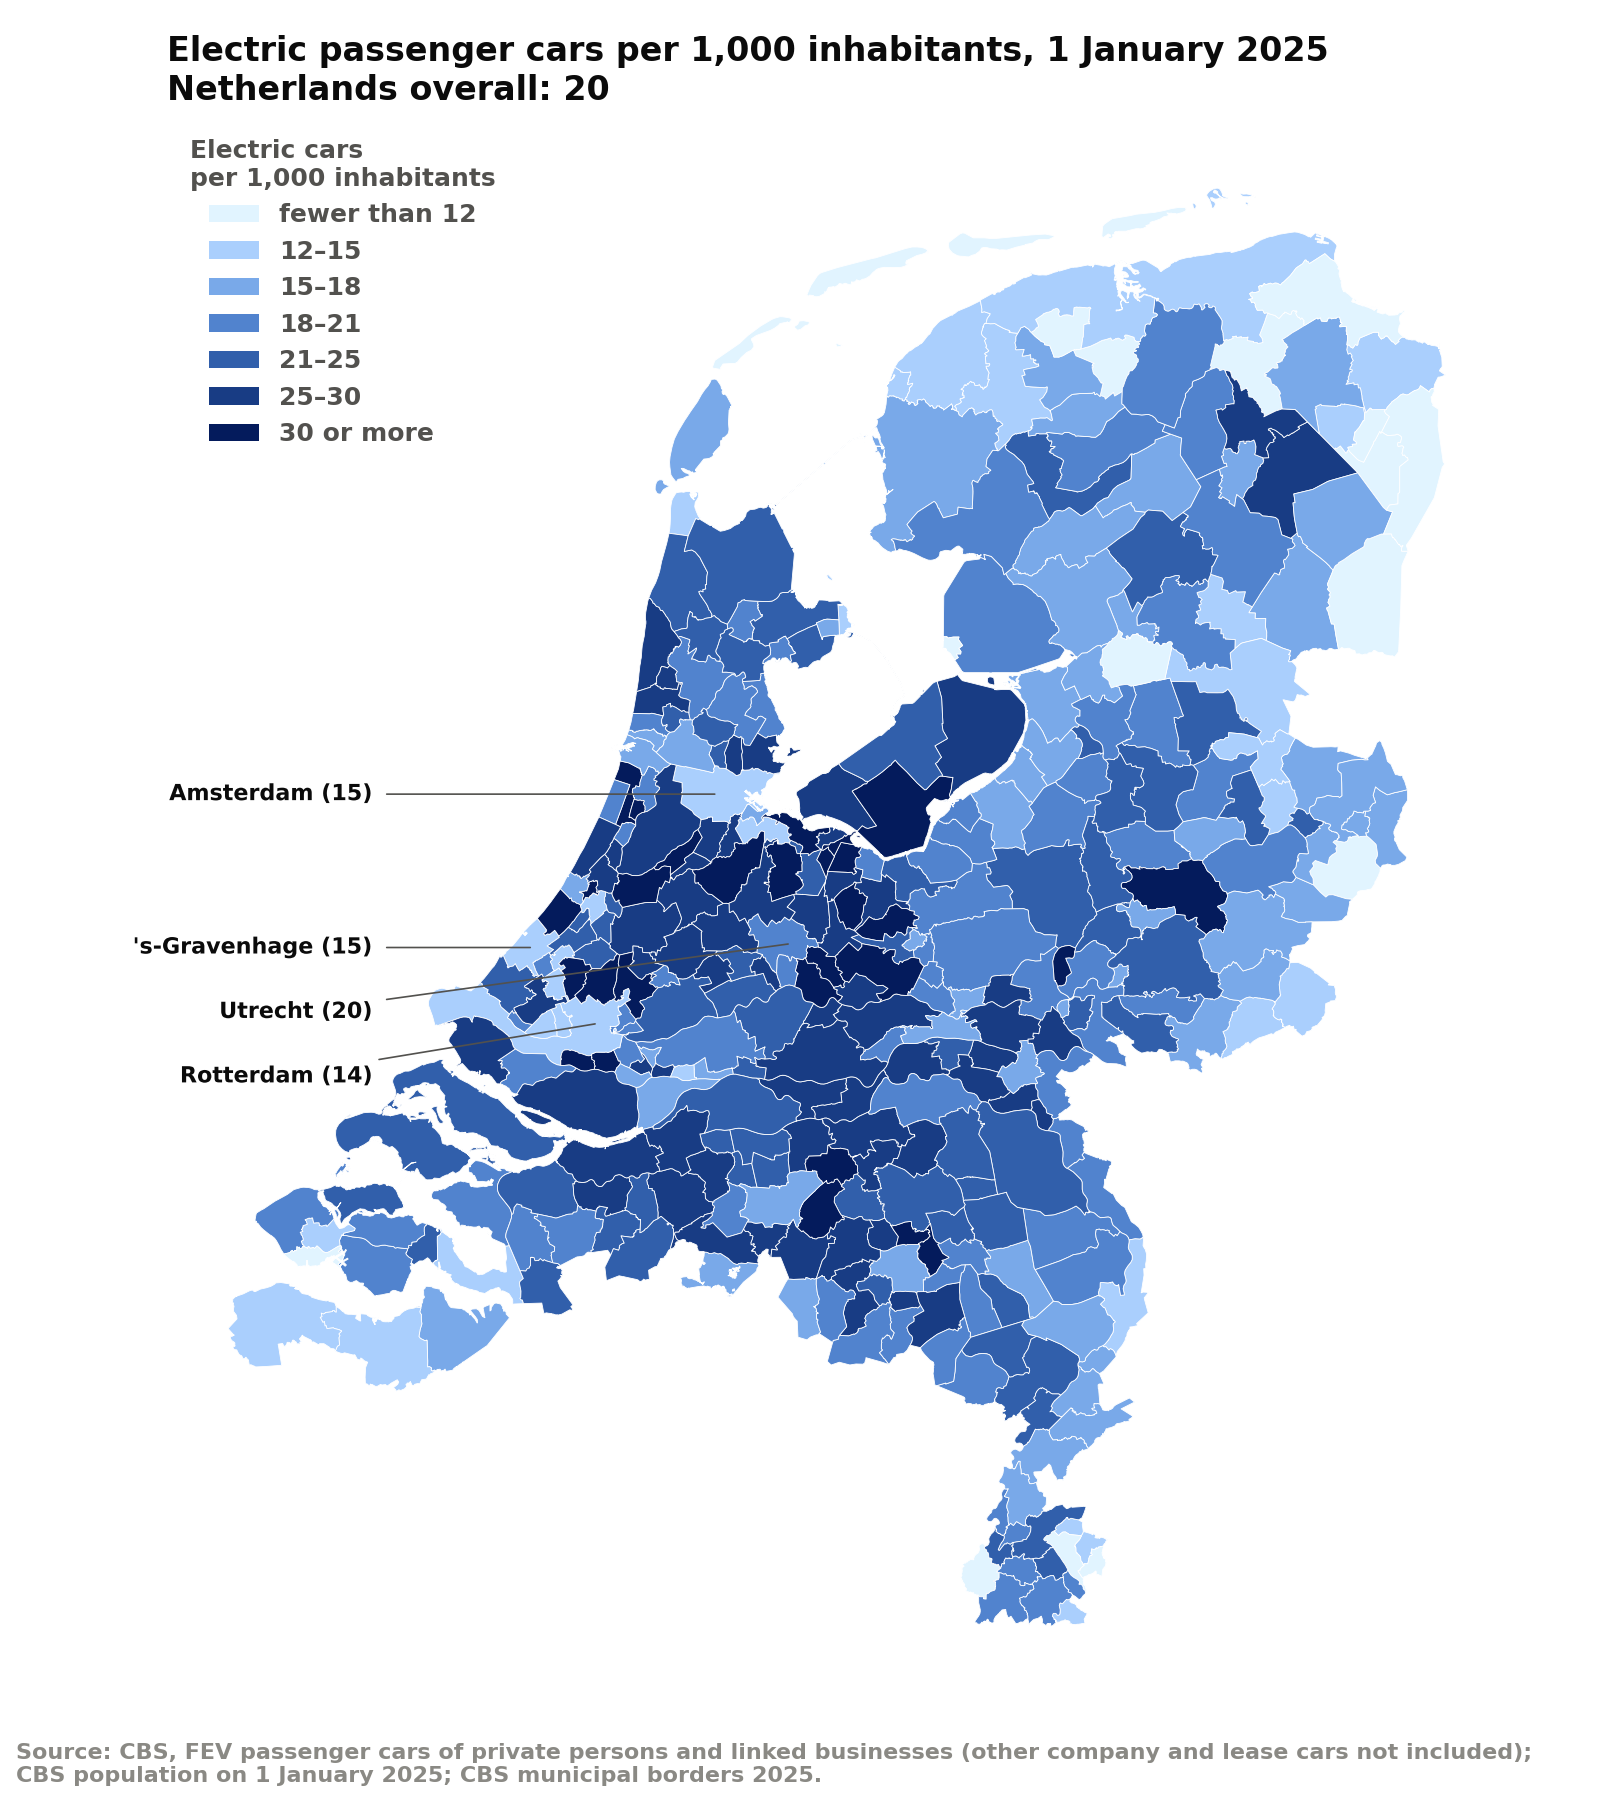

In [2]:
evs = plot_maps.ev_totals(gdf)
print(f"Electric cars: {evs[2022]:,.0f} on 1 January 2022, {evs[2025]:,.0f} on 1 January 2025 "
      f"({evs[2025] / evs[2022] - 1:+.0%})")
ev_maps = plot_maps.plot_ev_maps(gdf)
show(ev_maps[0], width=480)

**Figure 1.** Electric passenger cars per 1,000 inhabitants per municipality, 1 January 2025.

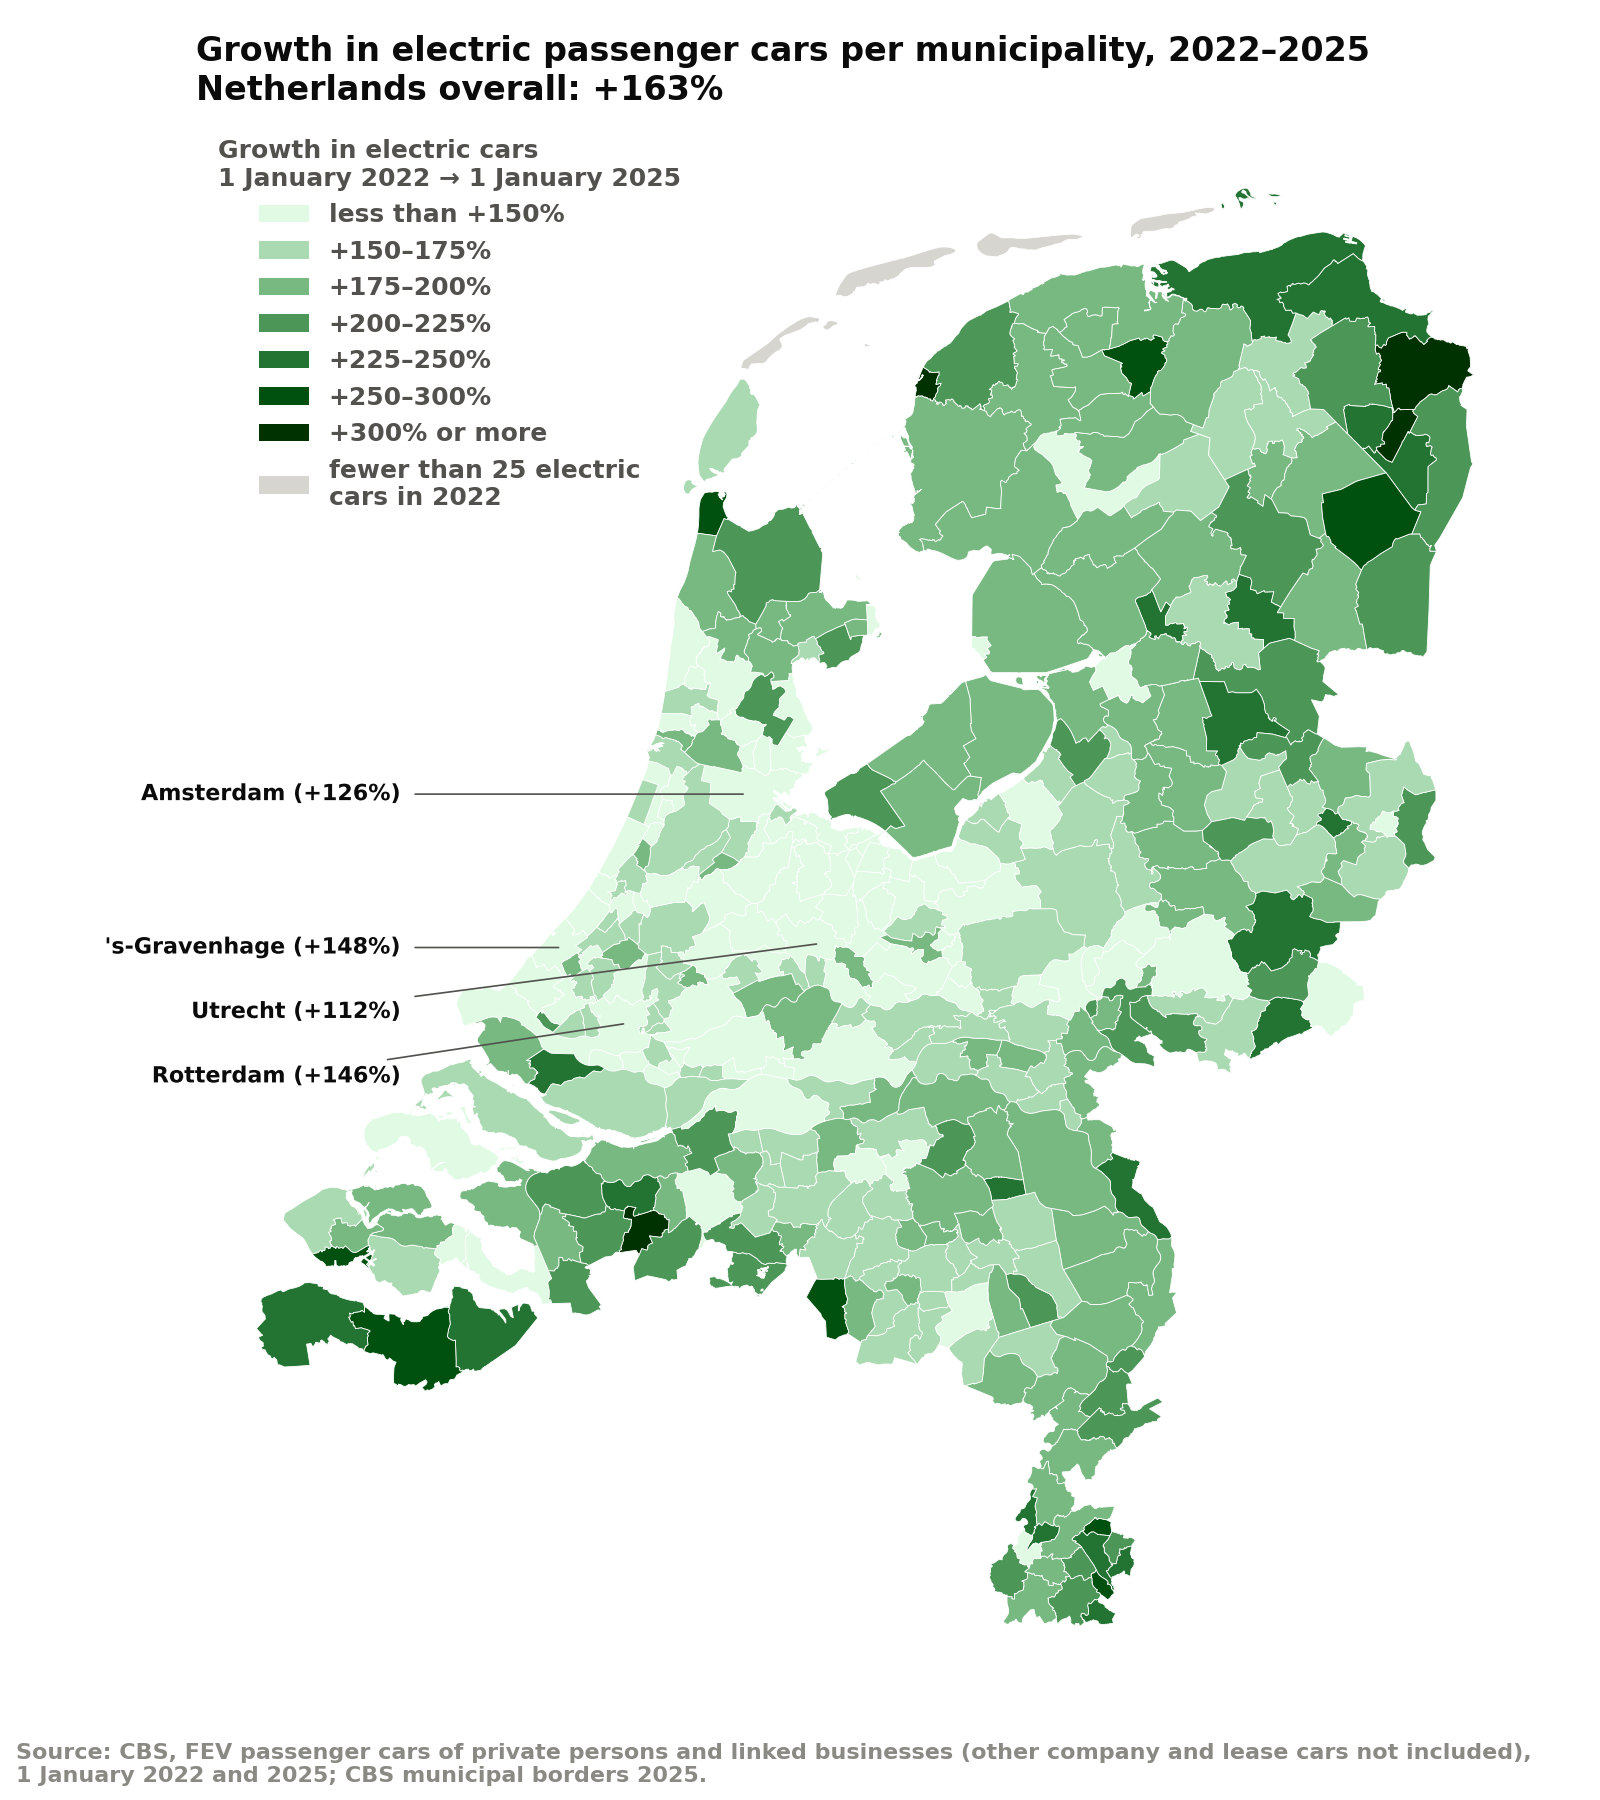

In [3]:
show(ev_maps[1], width=480)

**Figure 2.** Growth in the number of electric passenger cars per municipality, 1 January 2022 – 1 January 2025.

**Analysis**

The number of electric passenger cars more than doubled in every municipality that had at least 25 electric cars in 2022. Nationally it grew from about 137,000 on 1 January 2022 to about 361,000 on 1 January 2025 (+163%), reaching 20 electric cars per 1,000 inhabitants.

EV ownership per inhabitant is highest in the suburban municipalities around Amsterdam, Utrecht and 's-Gravenhage, and lowest in the north-east and on the Wadden Islands (Figure 1).

The growth map (Figure 2) shows a different pattern. The Randstad grew relatively slowly (Utrecht +112%, Amsterdam +126%, Rotterdam +146%, 's-Gravenhage +148%), while the north-east, Zeeuws-Vlaanderen and parts of Limburg grew fastest, often by more than +225%. The municipalities with the most EVs per inhabitant are therefore not the ones where the fleet grew fastest: EV adoption is spreading from the early-adopting urban and suburban areas to the rest of the country.

## Sub-question 2: How has the number of public charging points developed across Dutch municipalities between 2022 and 2025?

Public charging points are the sum of regular public, regular semi-public and fast (> 50 kW) charging points in the RVO data, counted in December of each year. Private charging points at homes and companies are not included.

In [4]:
plot_maps.charge_point_totals().style.format("{:,.0f}")

,Regulier Publiek,Regulier Semi-publiek,Snellaadpunten (>50 kW),Total
December,,,,
2022,"51,671","31,216","2,256","85,143"
2023,"69,829","40,386","3,007","113,222"
2024,"92,989","47,222","4,176","144,387"
2025,"108,481","72,883","5,733","187,097"


**Table 1.** Public charging points in the Netherlands per type, December 2022–2025 (without the six municipalities that have no data).

Saved figure to figures/charge_points_map.png


Saved figure to figures/charge_points_per_1000_inhabitants_map.png


Saved figure to figures/charge_points_growth_map.png


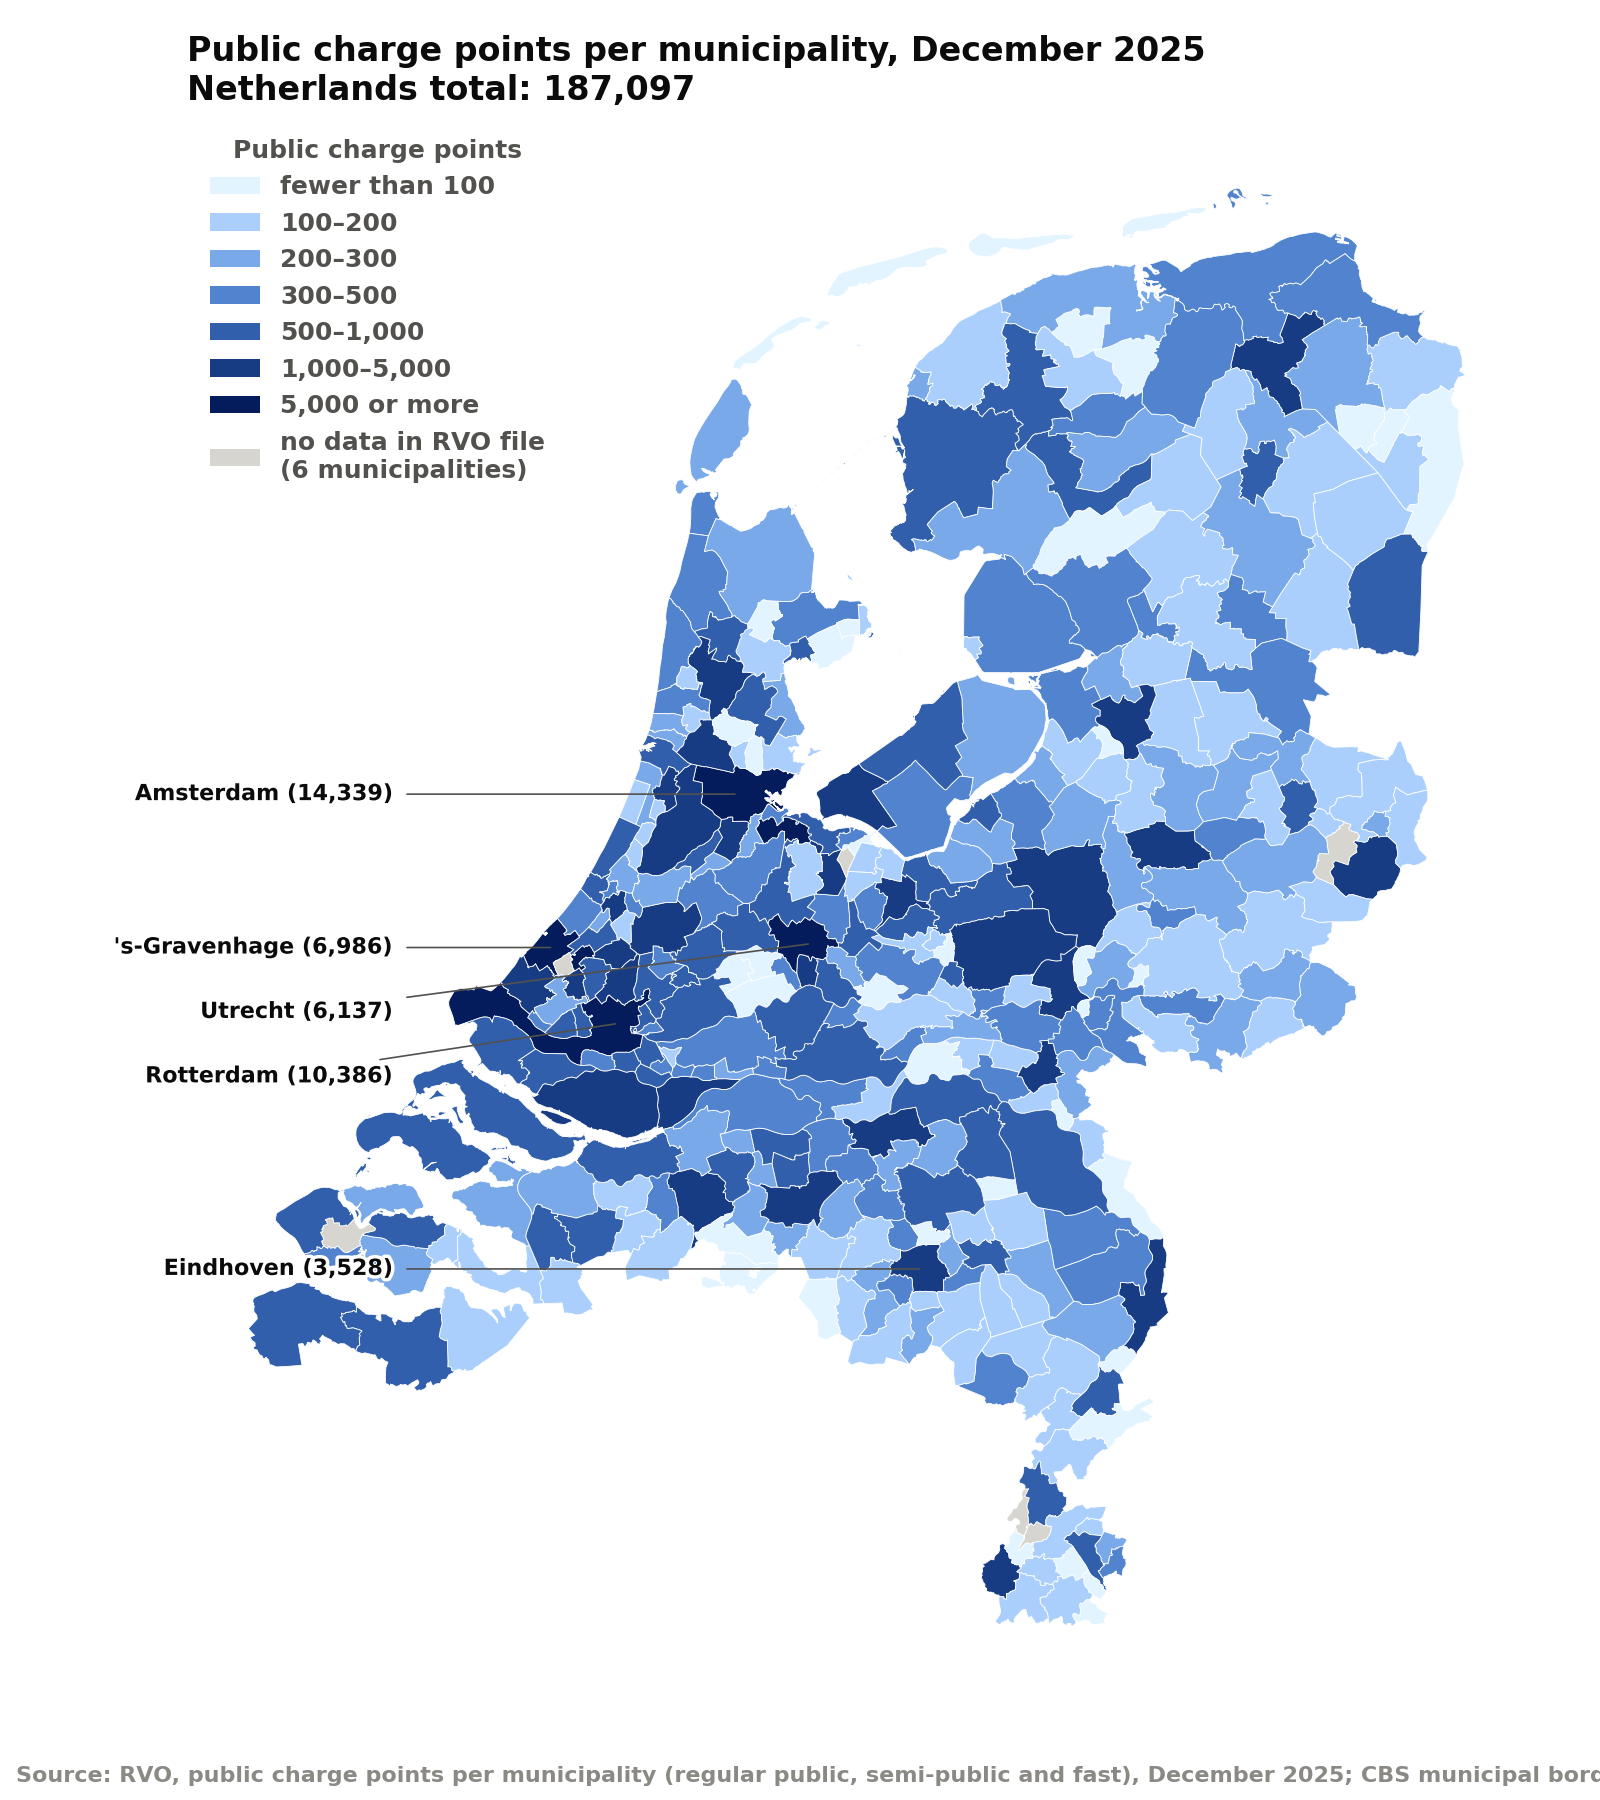

In [5]:
charge_point_maps = plot_maps.plot_charge_point_maps(gdf)
show(charge_point_maps[0], width=480)

**Figure 3.** Public charging points per municipality, December 2025.

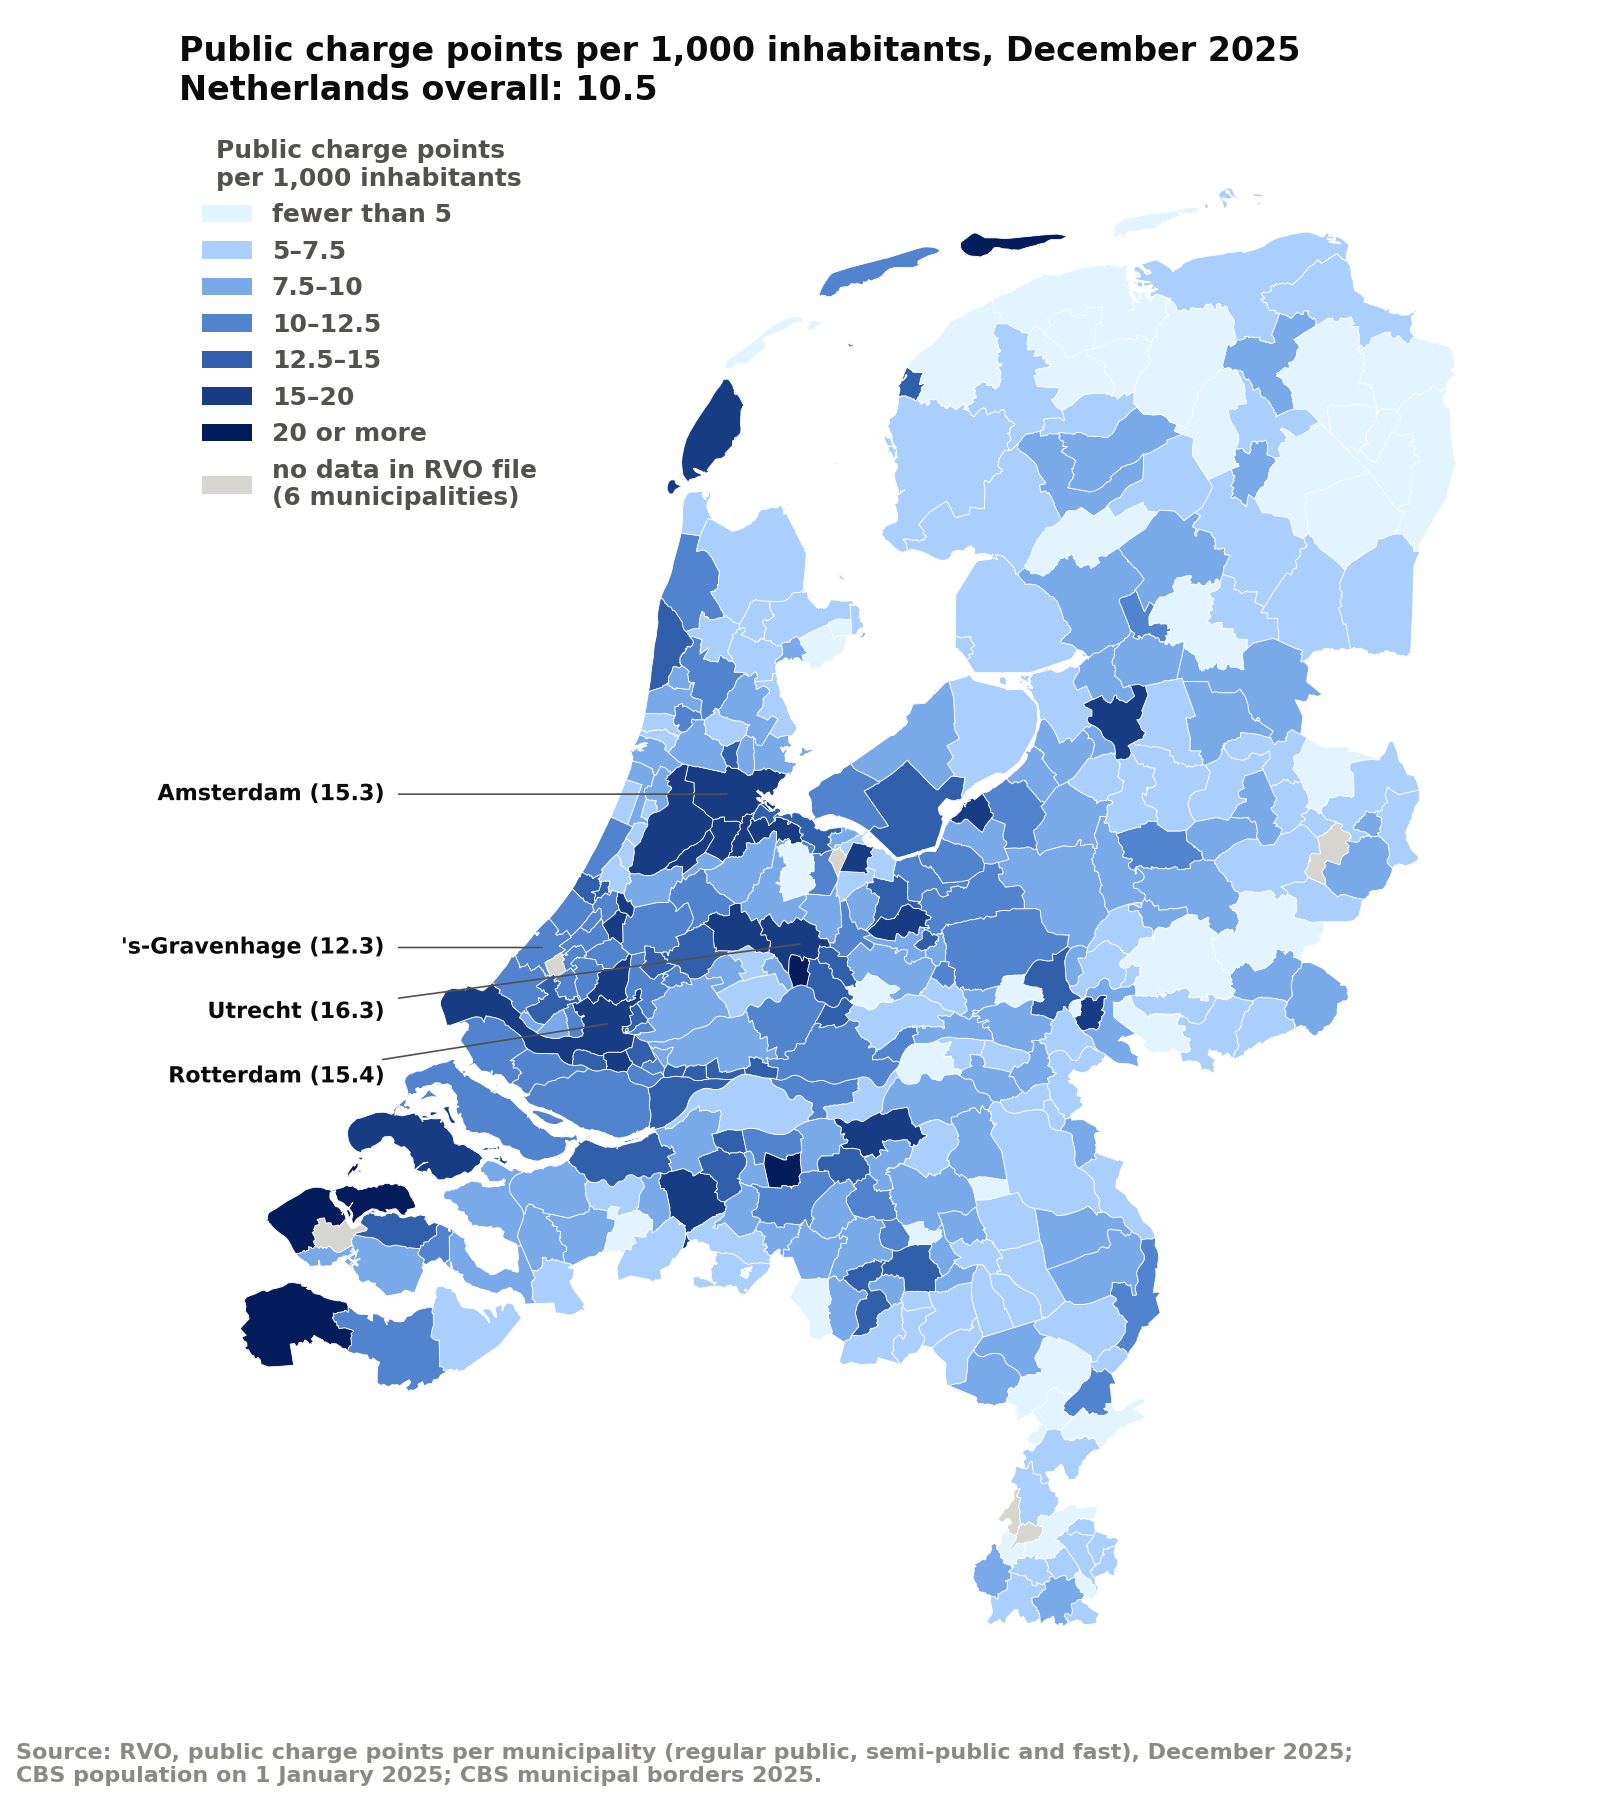

In [6]:
show(charge_point_maps[1], width=480)

**Figure 4.** Public charging points per 1,000 inhabitants per municipality, December 2025.

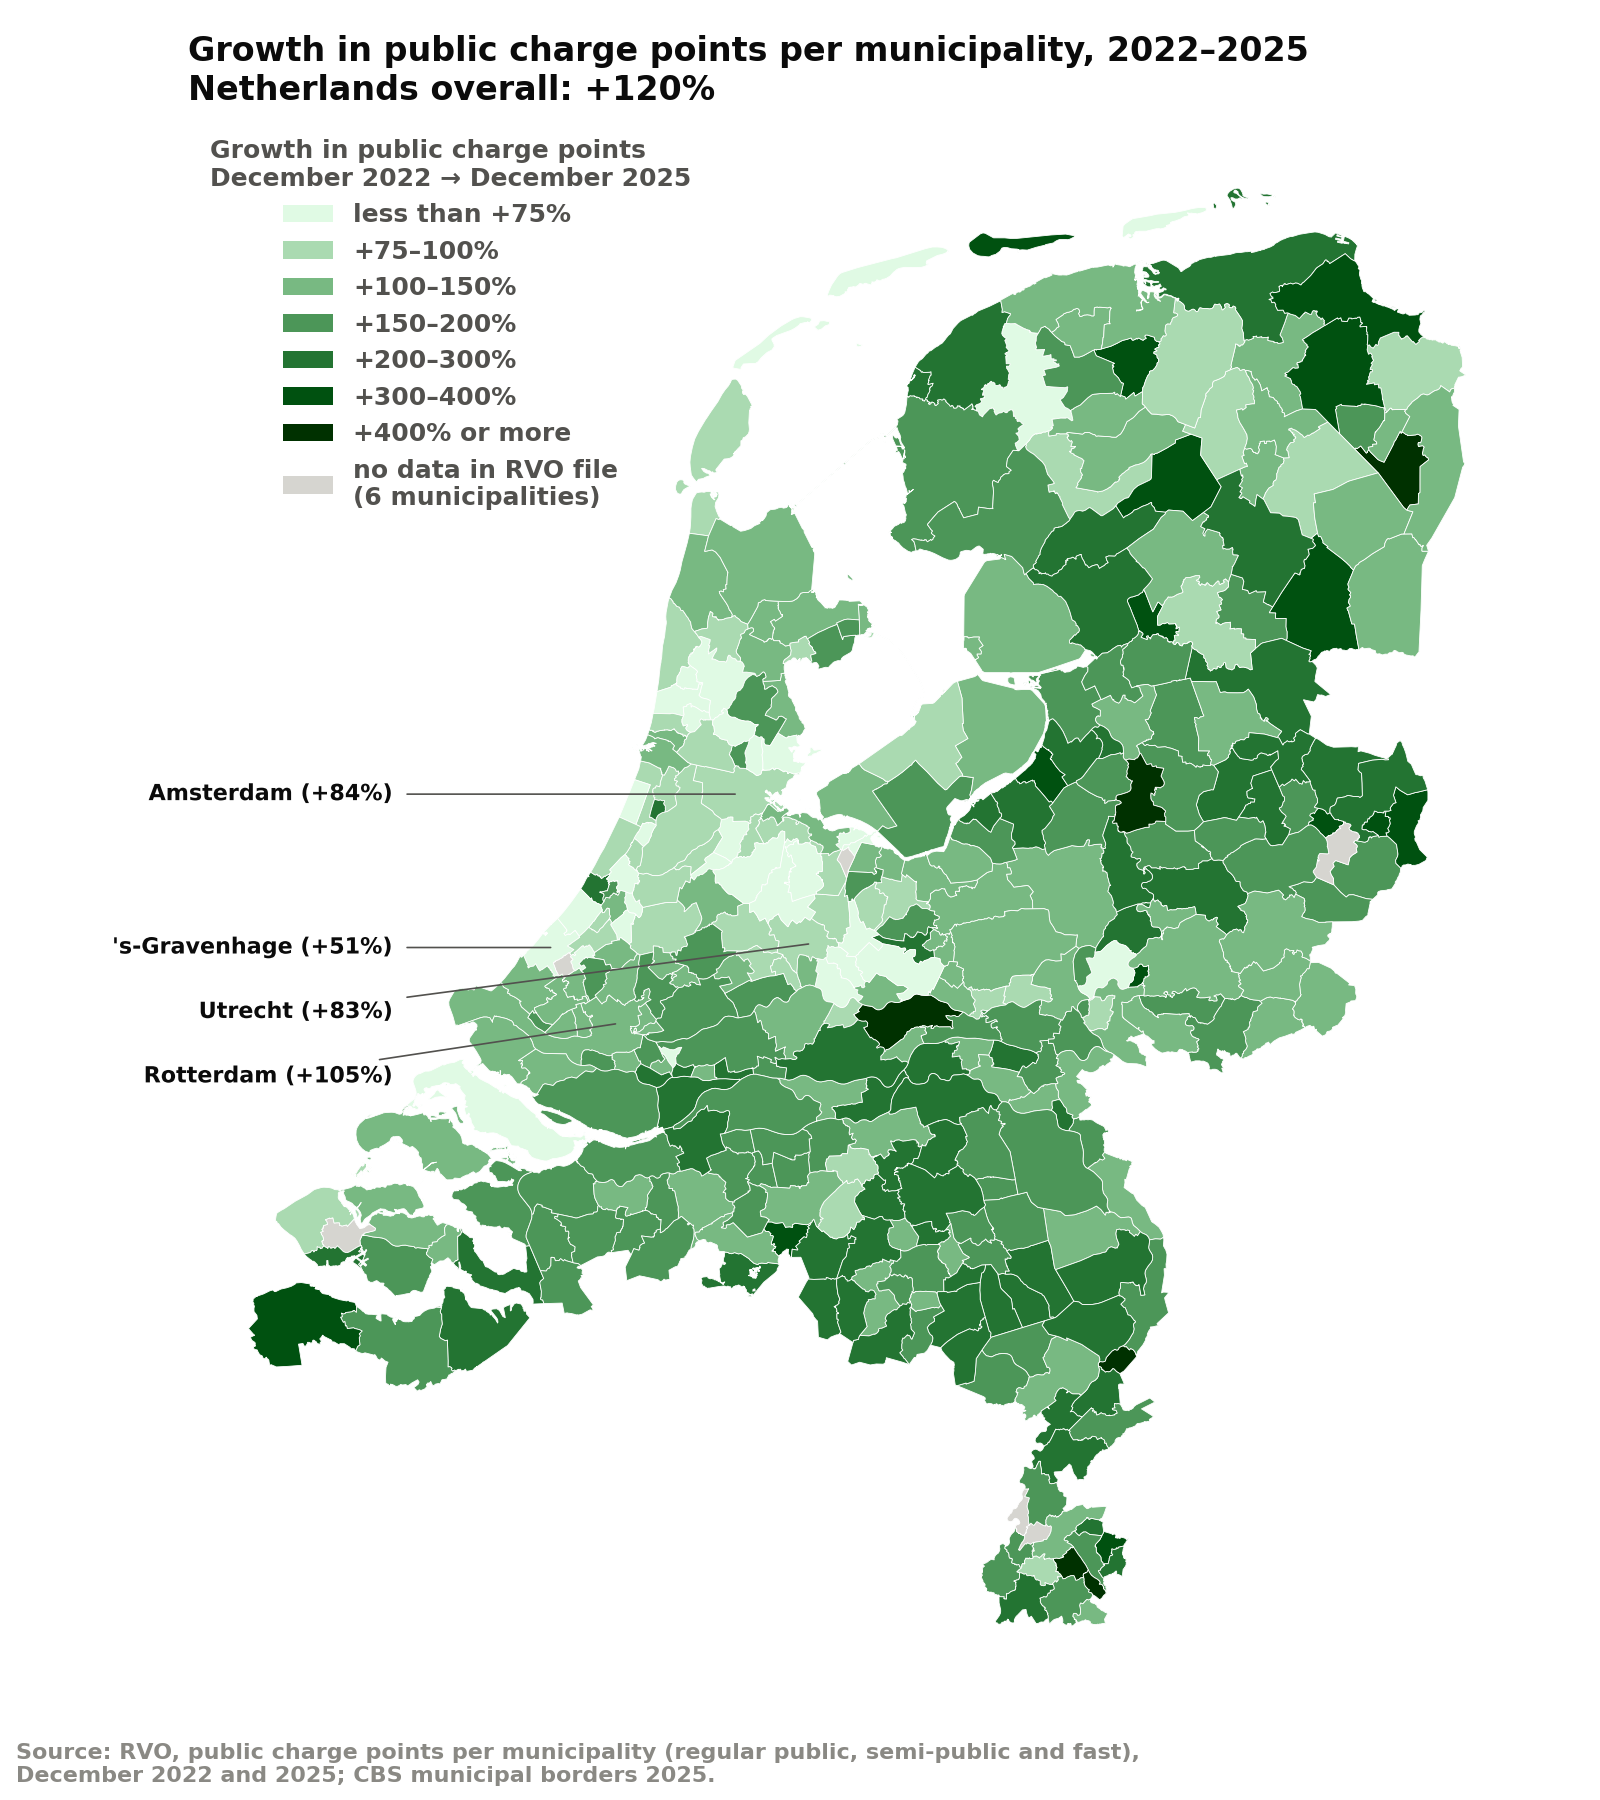

In [7]:
show(charge_point_maps[2], width=480)

**Figure 5.** Growth in the number of public charging points per municipality, December 2022 – December 2025.

**Analysis**

The number of public charging points grew from about 85,000 in December 2022 to about 187,000 in December 2025 (+120%). Regular public charging points grew from 51,700 to 108,500, semi-public points from 31,200 to 72,900 and fast charging points from 2,300 to 5,700 (Table 1). These growth figures describe the charging points on their own and cannot be compared directly with the growth of electric cars in sub-question 1 (+163%): electric cars are counted on 1 January and charging points in December, almost a year later. Sub-question 3 compares both at the same moments.

In absolute numbers the charging points are concentrated in the four large cities (Figure 3: Amsterdam 14,300, Rotterdam 10,400, 's-Gravenhage 7,000, Utrecht 6,100). Per inhabitant the picture is different (Figure 4): the national average is 10.5 per 1,000 inhabitants, but the highest values are in tourist municipalities on the Zeeland coast and the Wadden Islands (Sluis 41.6, Noord-Beveland 29.0, Veere 22.8). These charging points mainly serve visitors, not residents. The lowest values are in the north-east, for example Pekela (1.1) and Dantumadiel (1.4).

The growth map (Figure 5) mirrors the EV growth map (Figure 2): growth was slowest in the Randstad ('s-Gravenhage +51%, Utrecht +83%, Amsterdam +84%), which already had a dense network in 2022, and fastest in the more rural municipalities in the east and south.

Six municipalities (Beek, Hengelo, Laren, Middelburg, Rijswijk and Stein) have no data in the RVO file. They probably have names that exist in more than one province, so they are shown as missing rather than as zero. They are also missing from the national totals above.

## Sub-question 3: Which Dutch municipalities show a match or mismatch between charging infrastructure availability and EV adoption between the end of 2022 and the end of 2024?

To compare charging points and electric cars at the same moment, this sub-question uses the charging points of December and the electric cars of 1 January of the following year (see Data preparation). It covers the end of 2022 to the end of 2024, for the 333 municipalities with charging-point data and at least 25 EVs at the end of 2022.

Three analyses compare the EV data with the charging-point data:

1. **EVs per public charging point (CP)** at the end of 2022 and 2024. If this ratio rises, charging infrastructure has not kept pace with EV growth.
2. **Trend line.** Do municipalities where the number of EVs grew more also add more charging points? Both increases are taken per 1,000 inhabitants, because in absolute numbers both mainly measure the size of a municipality. A trend line through all municipalities gives the expected number of new charging points for each municipality's EV growth. Municipalities far above or below the line are where charging and EV growth do not match.
3. **Population density.** In rural municipalities more people can charge at home on their own driveway, so fewer public charging points per EV are needed. Comparing municipalities by density checks whether a mismatch is real or just a difference in parking.

### 3.1 EVs per public charging point, end of 2022 – end of 2024

In [8]:
national, changed = charging_vs_evs.evs_per_charge_point(matched, analysis)
kept_pace = (analysis["evs_per_cp_change"] <= 0).sum()
print(f"Charge points kept pace with EVs (ratio did not rise) in {kept_pace} of "
      f"{len(analysis)} municipalities")
national.style.format({"Electric cars": "{:,.0f}", "Public charge points": "{:,.0f}",
                       "EVs per charge point": "{:.2f}"})

Saved figure to figures/evs_per_charge_point_map.png
Charge points kept pace with EVs (ratio did not rise) in 167 of 333 municipalities


,Electric cars,Public charge points,EVs per charge point
End of year,,,
2022,"198,193","85,143",2.33
2023,"272,434","113,222",2.41
2024,"356,126","144,387",2.47


**Table 2.** Electric cars, public charging points and electric cars per public charging point in the Netherlands at the end of 2022, 2023 and 2024 (municipalities with charging-point data).

In [9]:
changed.style.format({"EVs per CP end 2022": "{:.2f}", "EVs per CP end 2024": "{:.2f}",
                      "Change": "{:+.0%}"})

,Municipality,EVs per CP end 2022,EVs per CP end 2024,Change
Charging fell behind most,Terschelling,0.52,1.21,+131%
Charging fell behind most,Oldambt,3.15,5.84,+86%
Charging fell behind most,Uithoorn,2.58,4.28,+66%
Charging fell behind most,Zandvoort,2.49,4.03,+62%
Charging fell behind most,Vaals,2.13,3.45,+62%
Charging caught up most,Voerendaal,41.33,5.00,-88%
Charging caught up most,Simpelveld,14.14,4.85,-66%
Charging caught up most,Buren,15.44,5.57,-64%
Charging caught up most,Olst-Wijhe,14.13,6.09,-57%
Charging caught up most,Goirle,6.26,3.06,-51%


**Table 3.** The five municipalities where the number of electric cars per public charging point rose most (charging fell behind) and fell most (charging caught up), end of 2022 – end of 2024.

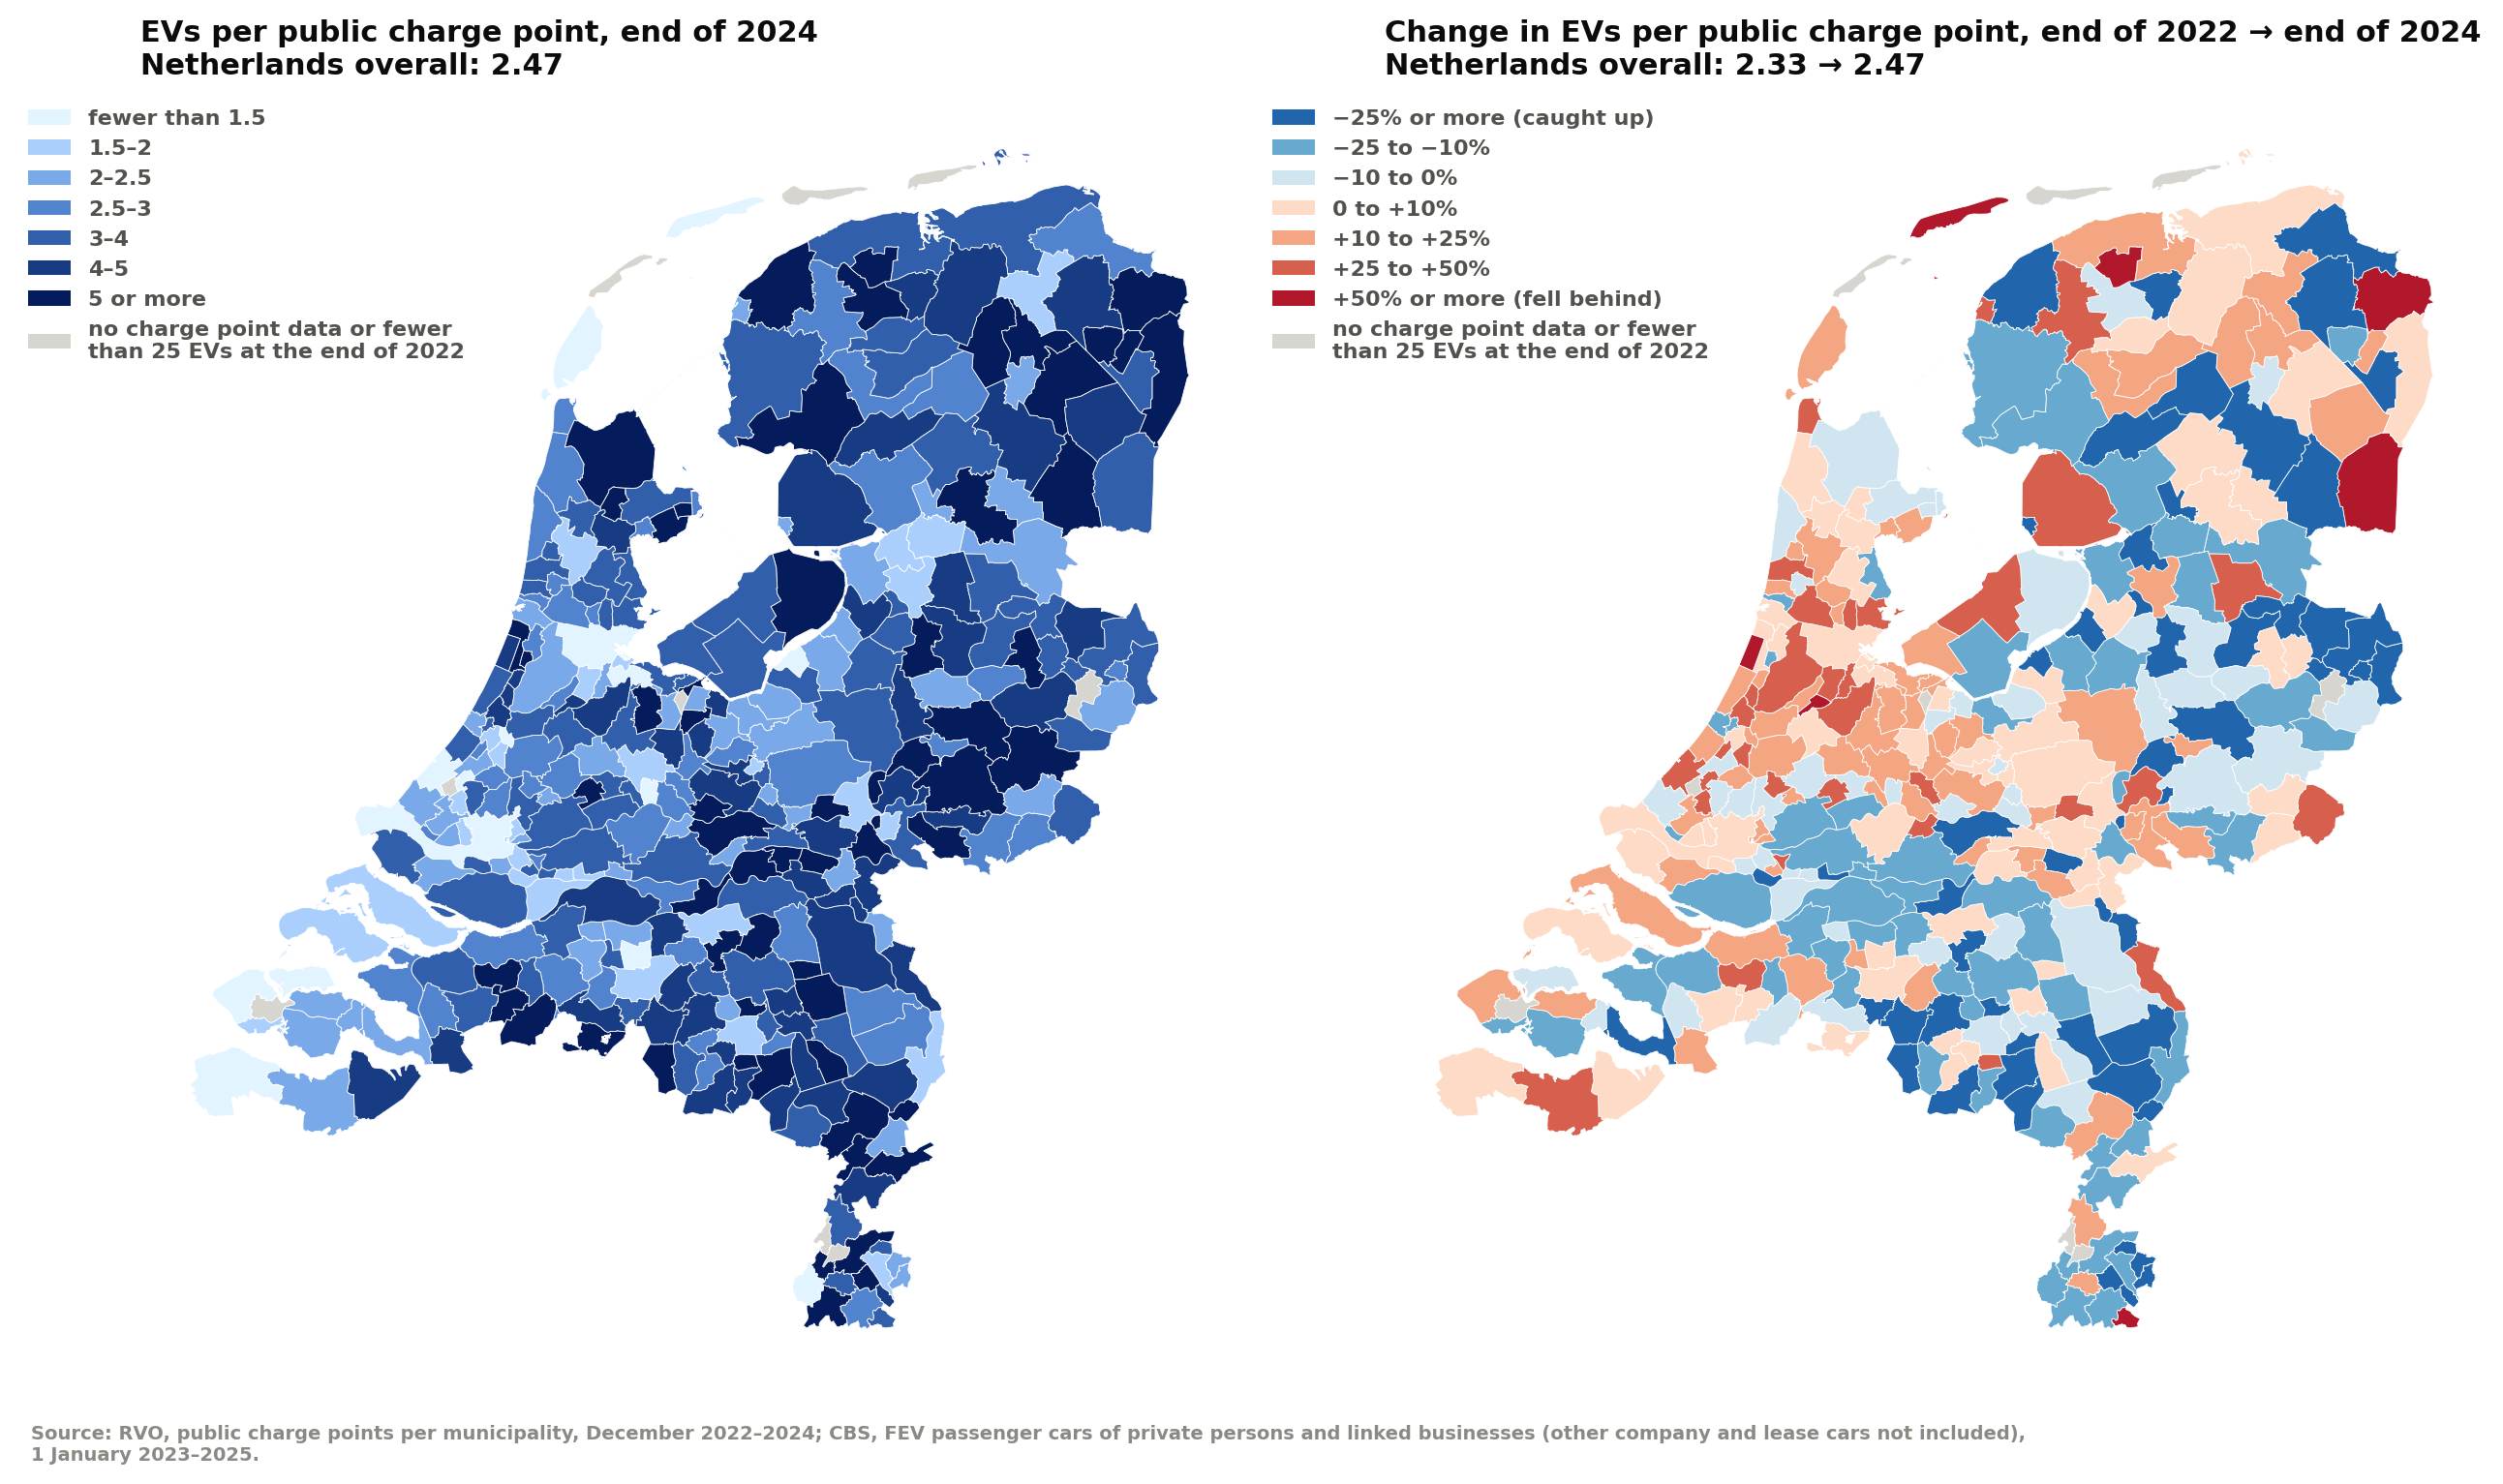

In [10]:
show(FIG_DIR / "evs_per_charge_point_map.png", width=900)

**Figure 6.** Electric cars per public charging point per municipality at the end of 2024 (left) and its change since the end of 2022 (right).

**Analysis**

Nationally, the number of electric cars per public charging point rose from 2.33 at the end of 2022 to 2.47 at the end of 2024, because the number of EVs grew faster (+80%) than the number of public charging points (+70%) (Table 2). The ratio rose in both years. Charging points grew at least as fast as EVs in 167 of the 333 municipalities; in the other 166 the ratio went up.

Figure 6 and Table 3 show both sides. The ratio rose most in Oldambt in the north-east of Groningen, in Uithoorn and Zandvoort in Noord-Holland and in Vaals in Limburg; in Oldambt there are now almost 6 EVs per public charging point. Terschelling is a special case: it has few electric cars (47) and lost charging points (from 48 to 39). The ratio fell most in municipalities that had very few charging points at the end of 2022, such as Voerendaal (41 to 5.0 EVs per charging point), Simpelveld, Buren and Olst-Wijhe. These municipalities caught up, while many municipalities that already had a dense network fell behind.

### 3.2 Trend line: does charging-point growth follow EV growth?

Each dot in Figure 7 is a municipality. The horizontal axis shows the increase in electric cars per 1,000 inhabitants between the end of 2022 and the end of 2024, the vertical axis the increase in public charging points per 1,000 inhabitants. Dividing by the number of inhabitants is necessary: in absolute numbers, large municipalities have both many new EVs and many new charging points simply because they have many residents. The line is the trend through all municipalities (a linear regression). Figure 8 compares each municipality's new charging points with the number expected from the trend line.

Saved figure to figures/charge_point_vs_ev_growth.png


Saved figure to figures/charge_point_growth_vs_trend_map.png
R² per 1,000 inhabitants: 0.01; in absolute numbers: 0.83


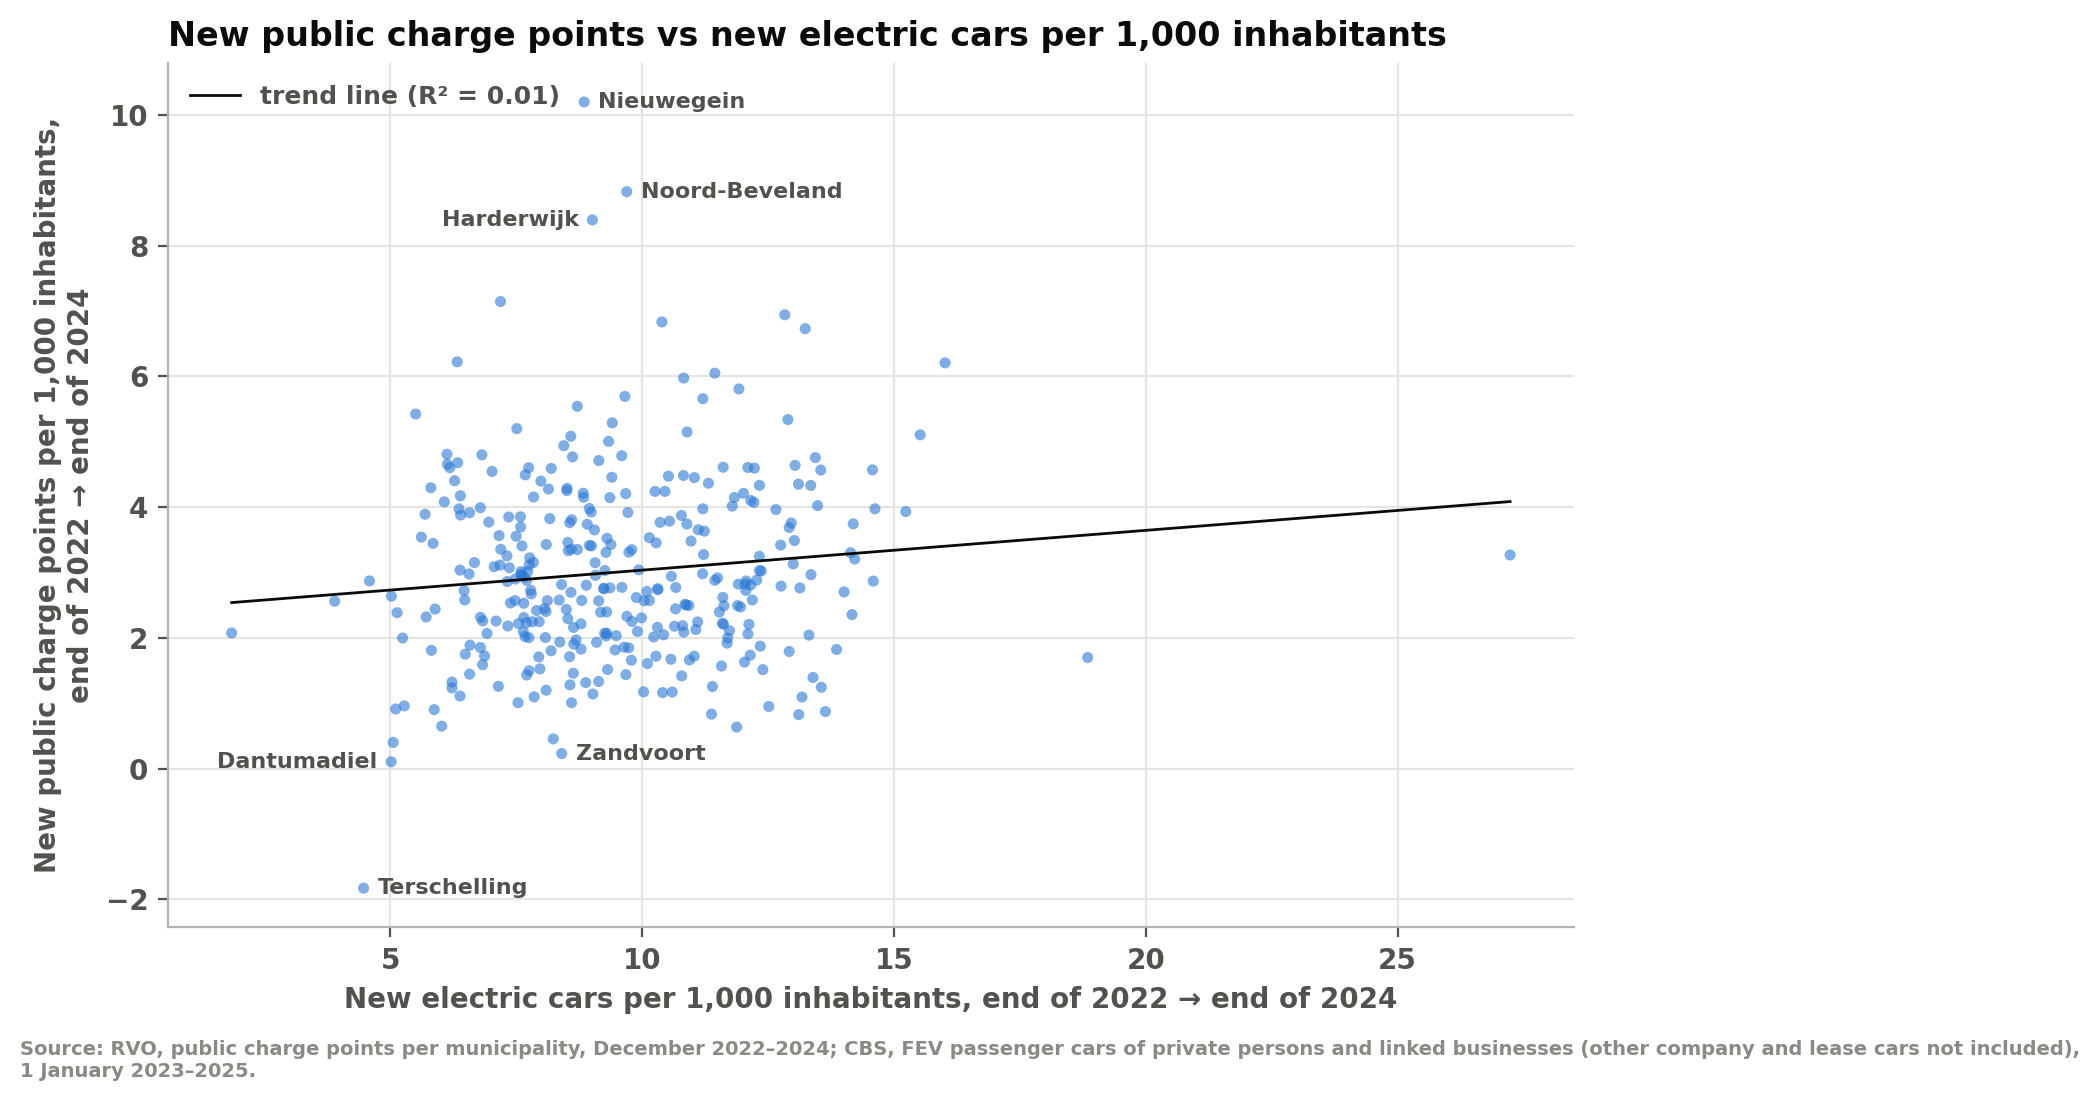

In [11]:
fit, outliers, classes = charging_vs_evs.trend_line(matched, analysis)
print(f"R² per 1,000 inhabitants: {fit['R² (per 1,000 inhabitants)']:.2f}; "
      f"in absolute numbers: {fit['R² (absolute numbers)']:.2f}")
show(FIG_DIR / "charge_point_vs_ev_growth.png", width=640)

**Figure 7.** New public charging points against new electric cars per municipality, both per 1,000 inhabitants, end of 2022 – end of 2024, with the trend line.

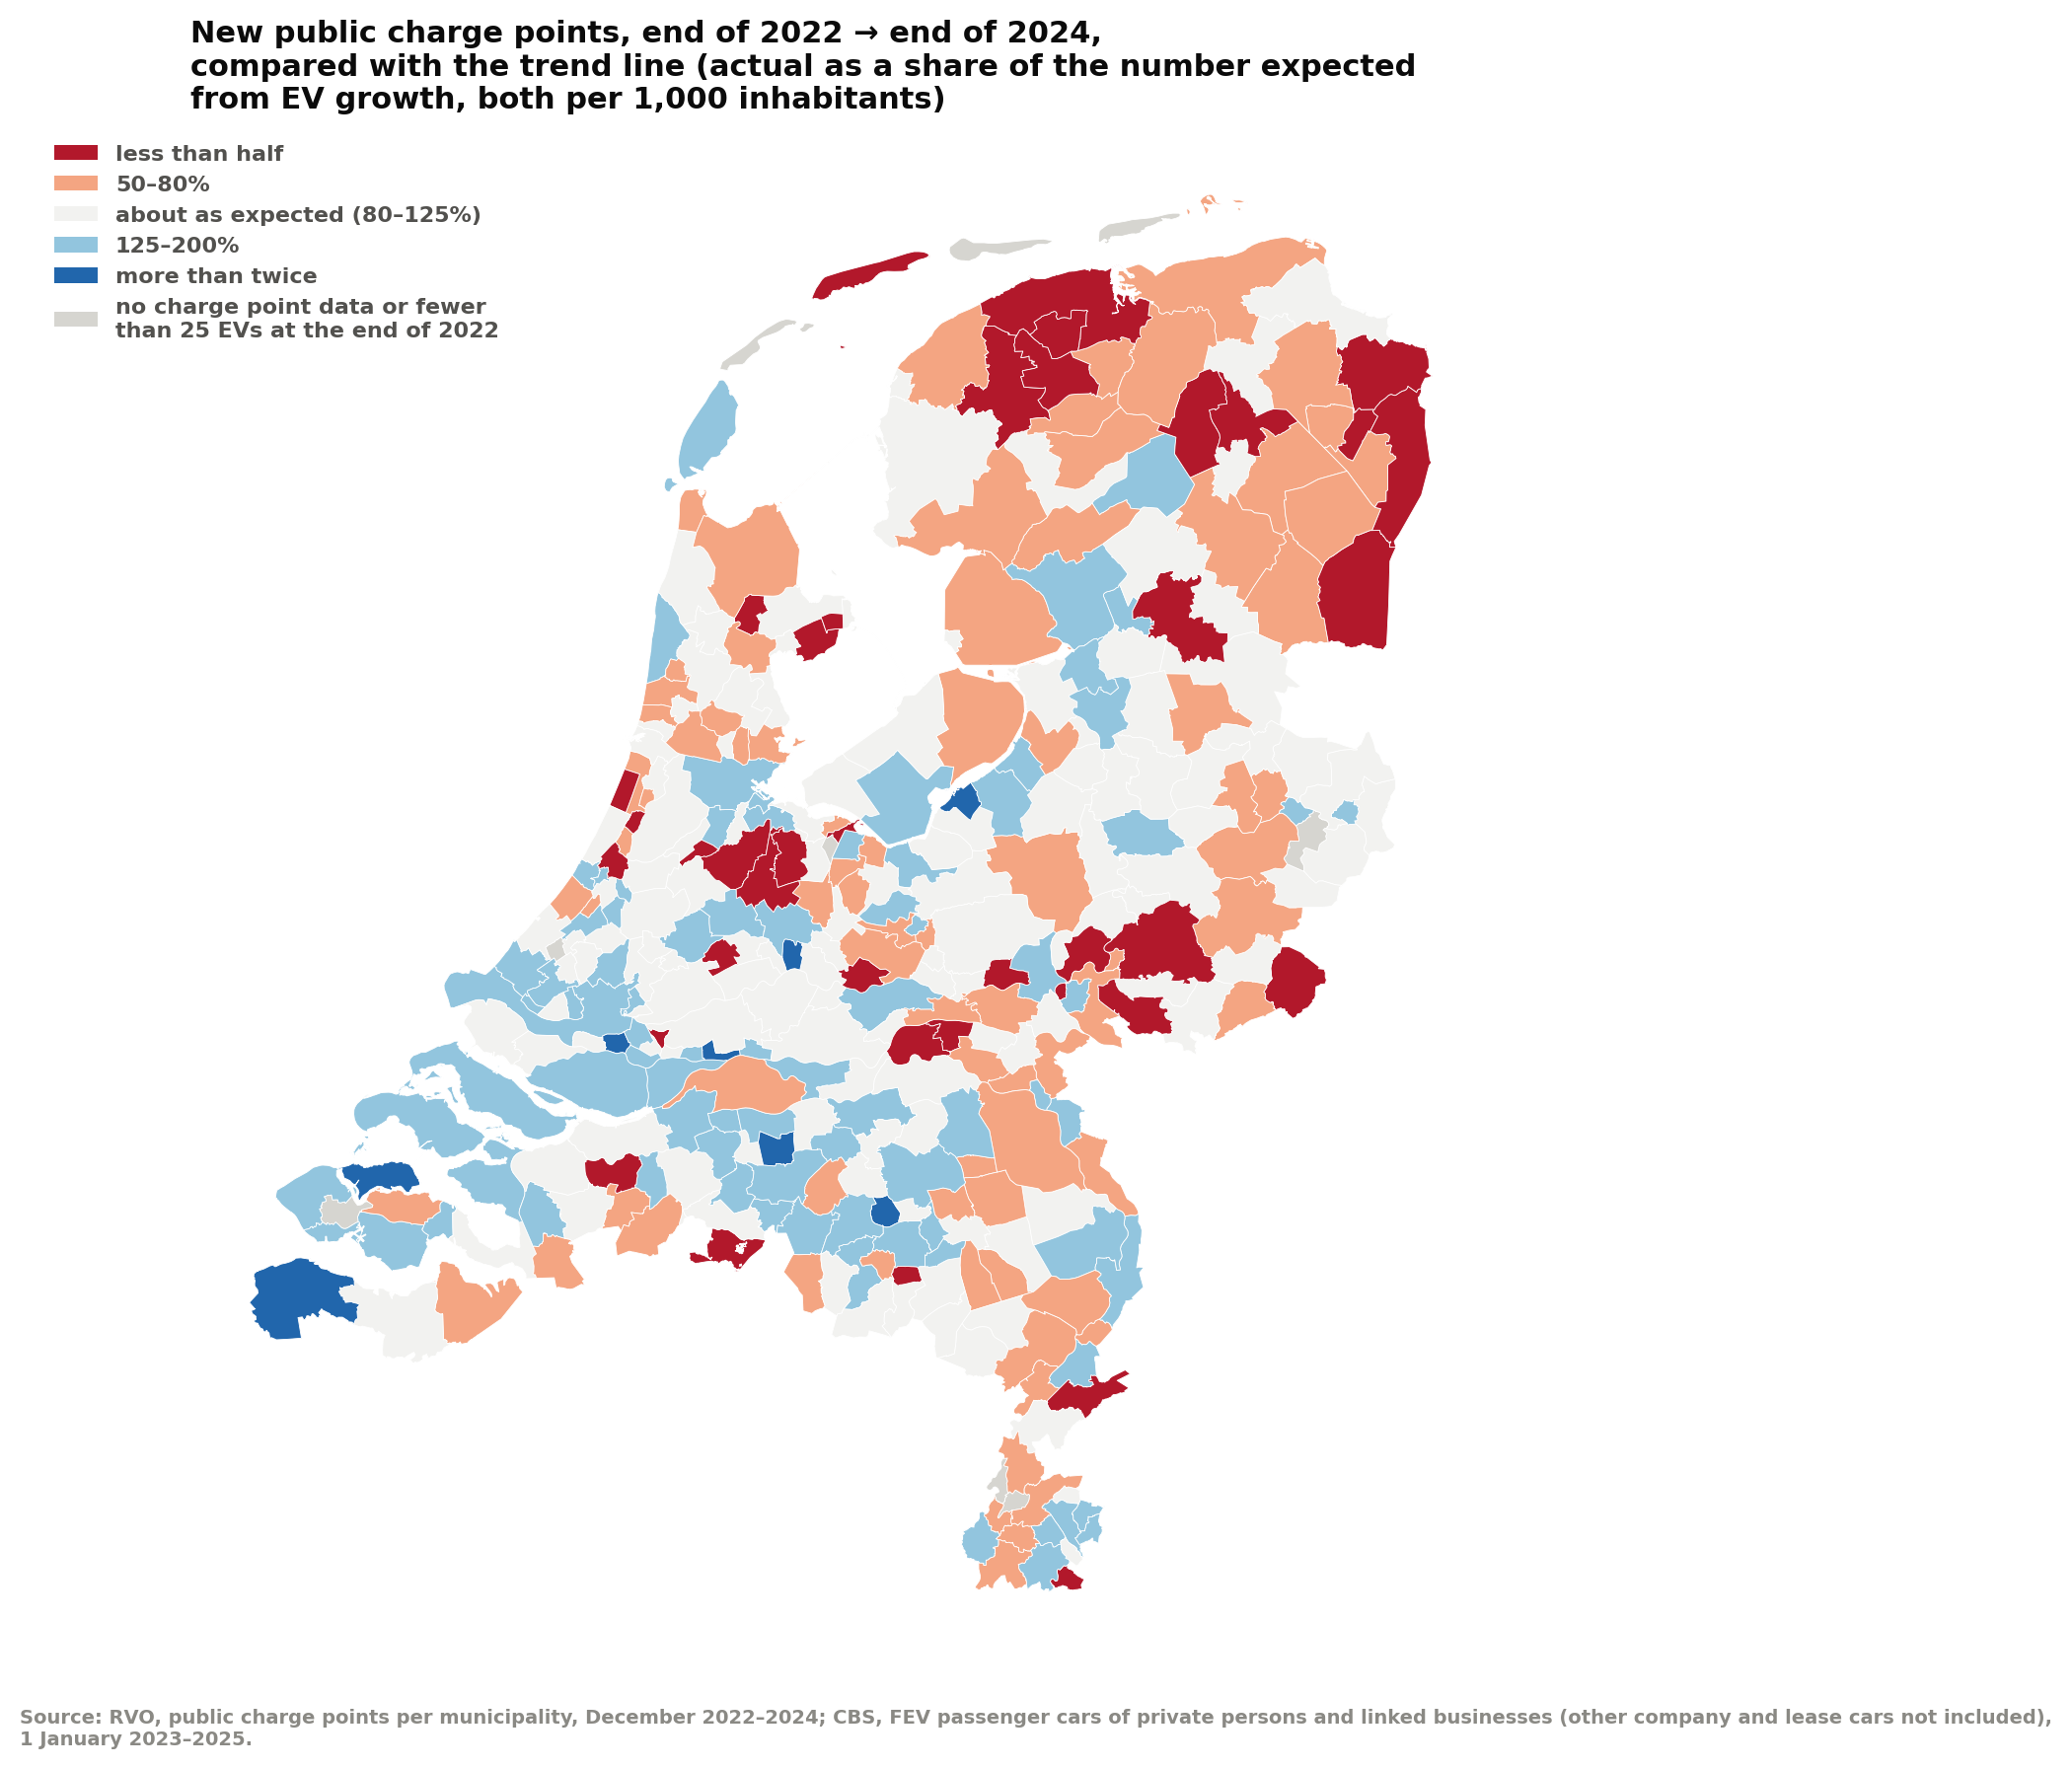

In [12]:
show(FIG_DIR / "charge_point_growth_vs_trend_map.png", width=520)

**Figure 8.** New public charging points per municipality, end of 2022 – end of 2024, as a share of the number expected from the trend line in Figure 7.

In [13]:
classes.to_frame()

,Municipalities
New charge points compared with the trend line,
less than half,39
50–80%,80
about as expected (80–125%),124
125–200%,82
more than twice,8


**Table 4.** Number of municipalities per class of Figure 8.

In [14]:
outliers.style.format({"New EVs per 1,000 inh.": "{:.1f}", "New CPs per 1,000 inh.": "{:.1f}",
                       "Actual / expected": "{:.0%}"})

,Municipality,"New EVs per 1,000 inh.","New CPs per 1,000 inh.",Actual / expected
Most new charge points,Nieuwegein,8.8,10.2,344%
Most new charge points,Noord-Beveland,9.7,8.8,292%
Most new charge points,Harderwijk,9.0,8.4,282%
Most new charge points,Sluis,7.2,7.1,249%
Most new charge points,Loon op Zand,10.4,6.8,223%
Fewest new charge points,Terschelling,4.5,-1.8,-68%
Fewest new charge points,Dantumadiel,5.0,0.1,4%
Fewest new charge points,Zandvoort,8.4,0.2,8%
Fewest new charge points,Pekela,5.1,0.4,15%
Fewest new charge points,Oldambt,8.2,0.5,16%


**Table 5.** The five municipalities with the most and the fewest new public charging points compared with the trend line.

**Analysis**

The trend line in Figure 7 is almost flat and the dots are widely scattered around it: municipalities where the number of EVs per inhabitant grew more did not add more public charging points per inhabitant. EV growth explains only 1% of the differences in charging-point growth between municipalities (R² = 0.01). Without the correction for size the two increases seem closely linked (R² = 0.83), but that only reflects that large municipalities have more of both.

Because the trend line is almost flat, the expected number of new charging points is about the same for every municipality (roughly 2.5 to 4 per 1,000 inhabitants). Figure 8 therefore mainly shows where charging points were added faster or slower than in a typical municipality. 124 of the 333 municipalities added about as many charging points as expected (80–125%, Table 4). The clearest deviations are (Table 5):

- **More than twice as many new charging points as expected** (8 municipalities), such as Nieuwegein, Noord-Beveland, Harderwijk, Sluis and Loon op Zand. Noord-Beveland, Sluis and Loon op Zand (home of the Efteling theme park) are tourist municipalities, where charging points also serve visitors rather than residents.
- **Less than half as many as expected** (39 municipalities), for example Dantumadiel, Zandvoort, Pekela and Oldambt, which added almost no charging points, and Terschelling, which lost charging points. In Dantumadiel, Pekela and Oldambt, in the north, charging infrastructure has not kept up with EV growth.

Figure 8 also shows a regional pattern: many municipalities in the south-west (Zeeland, Zuid-Holland and Noord-Brabant) added more charging points per inhabitant than expected, while many municipalities in the north (Groningen, Friesland and Drenthe) added fewer.

### 3.3 The role of population density

The 333 municipalities are split into four equal groups, from the least dense to the most dense. Figure 9 shows for each group the median number of EVs per public charging point at the end of 2022, 2023 and 2024; the dashed line is the national ratio.

In [15]:
density = charging_vs_evs.by_density(matched, analysis)
density.style.format({"Inhabitants per km²": "{:,.0f}", "EV growth": "{:+.0%}",
                      "CP growth": "{:+.0%}", "EVs per CP end 2022": "{:.2f}",
                      "EVs per CP end 2023": "{:.2f}", "EVs per CP end 2024": "{:.2f}"})

Saved figure to figures/evs_per_charge_point_by_density.png


,Municipalities,Inhabitants per km²,EV growth,CP growth,EVs per CP end 2022,EVs per CP end 2023,EVs per CP end 2024
Density group,,,,,,,
least dense 25%,84,168,+84%,+100%,4.37,4.54,4.20
2nd quarter,83,359,+81%,+82%,3.98,4.11,3.57
3rd quarter,83,699,+80%,+80%,3.05,3.34,3.31
most dense 25%,83,"2,070",+79%,+68%,2.23,2.37,2.44


**Table 6.** Medians per population-density group: growth of electric cars and public charging points, and electric cars per public charging point, end of 2022 – end of 2024.

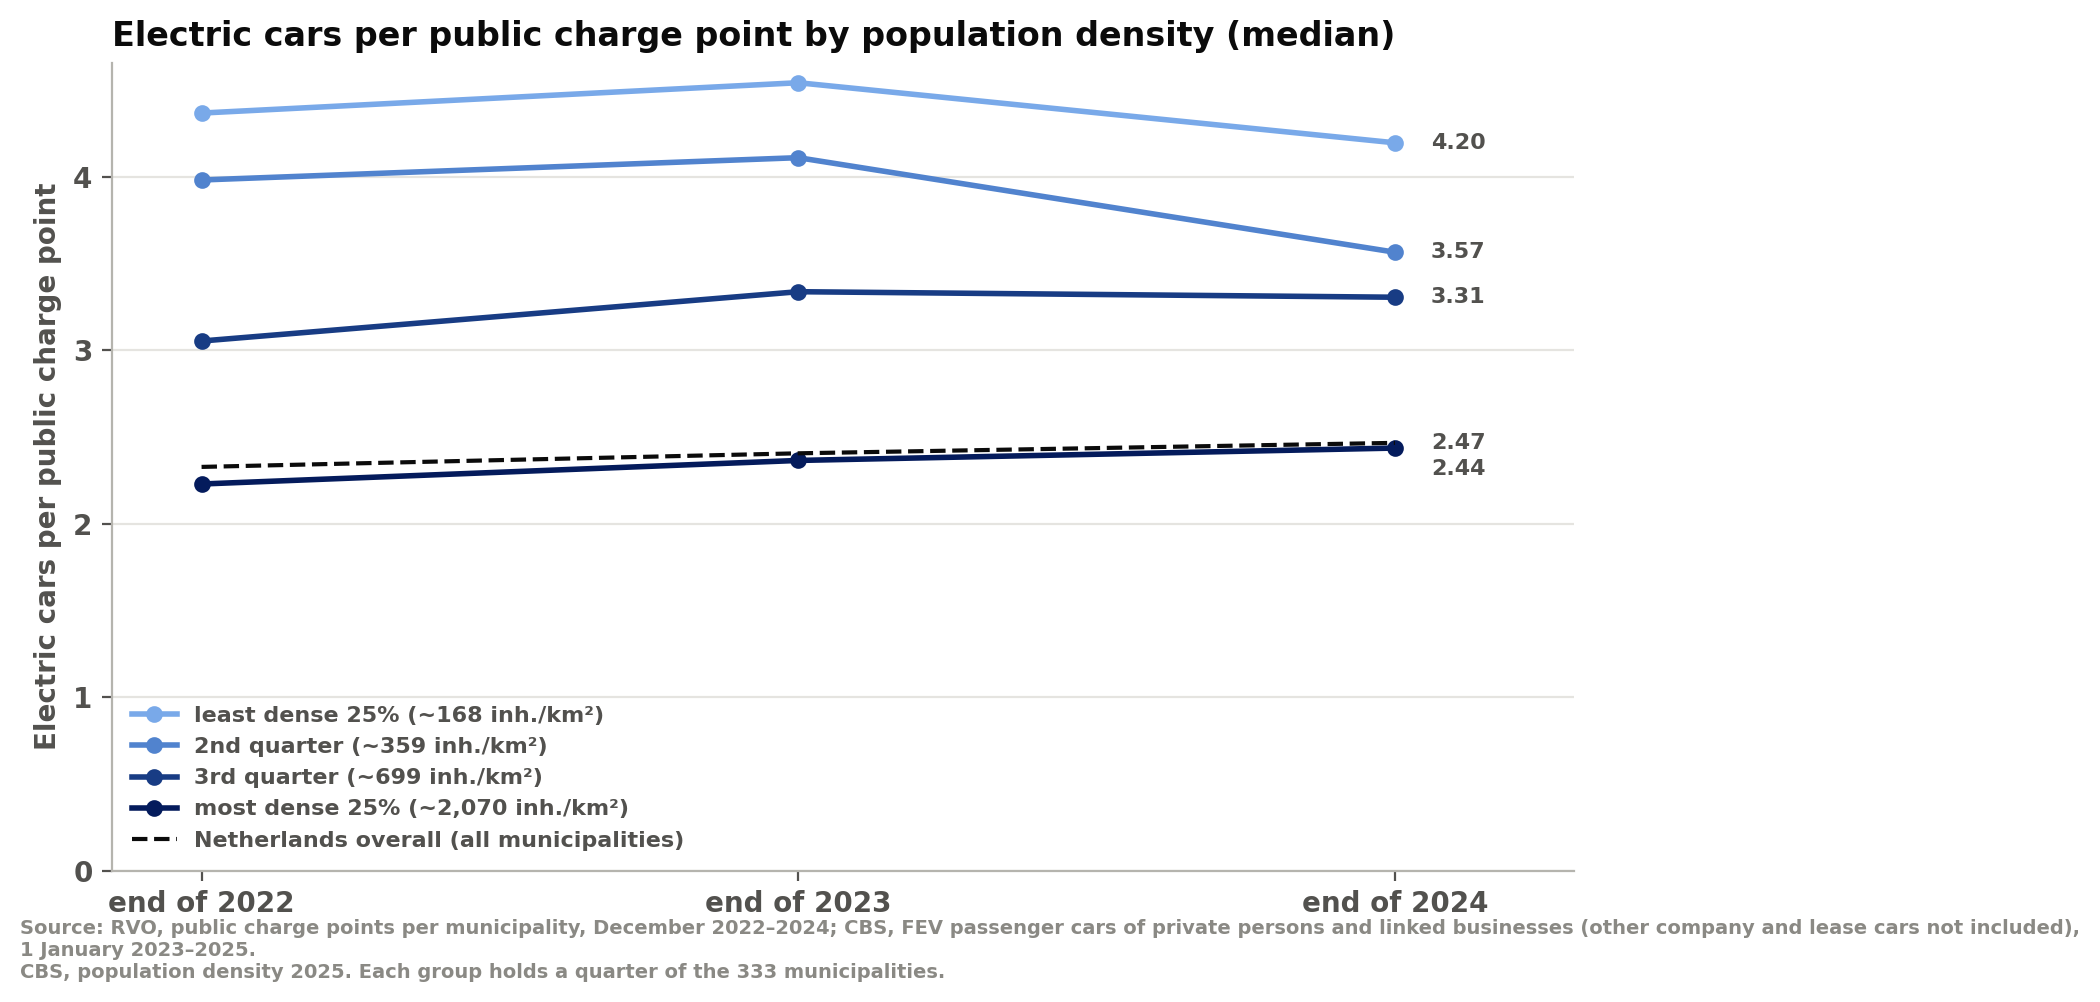

In [16]:
show(FIG_DIR / "evs_per_charge_point_by_density.png", width=640)

**Figure 9.** Median number of electric cars per public charging point per population-density group, end of 2022 – end of 2024.

**Analysis**

Sparsely populated municipalities have more EVs per public charging point (Figure 9): at the end of 2024 the median is 4.20 in the least dense group and 2.44 in the most dense group.

The change since the end of 2022 differs by group (Table 6). In the two least dense groups the ratio went down (4.37 to 4.20 and 3.98 to 3.57), because public charging points grew at least as fast as EVs. In the most dense group it rose every year, from 2.23 to 2.44: charging points there grew by a median of 68%, while EVs grew by 79%. EV growth was almost the same in all groups (+79% to +84%), so the difference comes from the growth of charging points.

This seems to contradict section 3.2, where many municipalities in the densely populated Zuid-Holland added more charging points than expected (Figure 8). Both are true. The most dense municipalities added the most charging points per inhabitant: a median of 3.4 per 1,000 inhabitants, against 2.5 in the least dense group. Because EV growth per inhabitant was about the same in both groups (a median of 8.6 new electric cars per 1,000 inhabitants), they also added more charging points per new electric car. But they started with a network twice as dense (a median of 5.0 charging points per 1,000 inhabitants at the end of 2022, against 2.5), so the same additions are a smaller percentage of what was already there. The least dense municipalities started with many EVs per charging point and the most dense with few, and the groups are growing towards each other.

In conclusion, the urban municipalities still have the most public charging points per EV. However, this is also where the number of EVs per charging point rose between 2022 and 2024. This matters because city residents usually cannot charge at home and depend on public charging points. In rural municipalities the higher number of EVs per charging point is less of a problem, because more people can charge on their own driveway (RVO et al., 2026).

# Conclusion

This project examined to what extent public charging infrastructure in Dutch municipalities has kept pace with the growth of electric passenger cars between 2022 and 2025.

**Sub-question 1: development of electric passenger cars.** The number of electric passenger cars grew from about 137,000 on 1 January 2022 to about 361,000 on 1 January 2025 (+163%) and more than doubled in every municipality with at least 25 EVs in 2022. EV ownership per inhabitant is highest around the large cities, but growth was fastest in the more rural and peripheral regions, such as the north-east, Zeeuws-Vlaanderen and Limburg. EV adoption is spreading from the early-adopting urban areas to the rest of the country.

**Sub-question 2: development of public charging points.** The number of public charging points grew from about 85,000 in December 2022 to about 187,000 in December 2025 (+120%). Most charging points are in the large cities, but per inhabitant the highest values are in tourist municipalities on the coast and the lowest in the north-east. As with EVs, growth was slowest in the Randstad, which already had a dense network in 2022, and fastest in rural municipalities.

**Sub-question 3: match and mismatch.** Compared at the same moments (end of 2022 to end of 2024), the growth of charging points does not follow the growth of EVs at municipal level. After correcting for the number of inhabitants, municipalities where the number of EVs grew more did not add more public charging points (R² = 0.01). Where charging points were added therefore depends on other factors than local EV growth. As a result, the growth did not match in many places:
 
- In tourist municipalities (Noord-Beveland, Sluis, Loon op Zand) charging points grew much faster than local EV numbers, because they also serve visitors.
- In some municipalities, especially in the north (Oldambt, Pekela, Dantumadiel) and parts of Noord-Holland (Uithoorn, Zandvoort), charging points fell clearly behind EV growth.
- Municipalities that had very few charging points at the end of 2022 caught up, while the dense urban municipalities fell behind: their median number of EVs per charging point rose from 2.23 to 2.44, whereas it went down in the least dense municipalities.

**Main research question.** Public charging infrastructure has only partly kept pace with the growth of electric passenger cars. Charging points grew strongly, but not as fast as the number of EVs: between the end of 2022 and the end of 2024, EVs grew by 80% and public charging points by 70%. These matched figures are lower than those of sub-questions 1 and 2 (+163% and +120%), which describe each dataset on its own over three years and are measured almost a year apart, so those two cannot be compared with each other. The municipalities where most charging points were added are not the ones where the number of EVs grew most. As a result, the number of EVs per public charging point rose from 2.33 to 2.47 nationally, and in half of the municipalities (166 of 333). The gap is most significant in the urban areas: they still have the most charging points per EV, but this is where the number of EVs per charging point rose most. Residents in urban areas depend most on public charging because they often cannot charge at home.

# Discussion

*To be written. Points to cover:*

## Limitations of the data

- **Definition of electric cars.** Only cars of private persons and linked businesses are included. Lease and company cars, a large part of all electric cars, are left out, although their drivers also use public charging points.
- **Semi-public charging points** (at supermarkets, offices and parking garages) are counted as public, although they are often only open at certain times or to customers.
- **Private charging points** at homes and companies are not in the data, while according to the *Ladder van Laden* most charging should happen there.
- **Six municipalities** (Beek, Hengelo, Laren, Middelburg, Rijswijk and Stein) have no charging-point data and are also missing from the national totals.
- **Small municipalities** react strongly to a few cars or charging points (for example Terschelling and the Wadden Islands).
- **Population and population density** are only used for 2025.

## Limitations of the method

- **Matching the dates** shortens sub-question 3 to two years (end of 2022 – end of 2024); the growth figures of sub-questions 1 and 2 cover three years and are measured about a year apart.
- **The number of charging points** says nothing about their charging power (kW) or how much they are used; the EU target (AFIR) is set in charging power.
- **Municipal averages** hide differences between neighbourhoods within a municipality.
- **Correlation, not causation**: the analysis cannot show whether charging points follow electric cars or electric cars follow charging points (feedback from the presentation). The trend line is a simple linear regression with one explanatory variable.
- **Population density as a proxy** for the share of residents who can charge at home; medians per density group.

## Recommendations and further research

- Repeat the analysis per neighbourhood (CBS *wijken en buurten*), where the need for public charging points is decided.
- Add charging power and the use (occupancy) of charging points.
- Include other explanations of EV growth, such as fuel prices, subsidies and income (feedback from the presentation).
- Compare municipal policies (charging points on request or placed in advance, regional concessions) to explain why municipalities differ.
- For policy: monitor the number of EVs per public charging point per municipality, with attention to the dense urban municipalities and the lagging municipalities in the north.

# References

Centraal Bureau voor de Statistiek. (2023). *Vertekening personenauto's naar gemeente 1-1-2022*. https://www.cbs.nl/nl-nl/longread/aanvullende-statistische-diensten/2023/vertekening-personenauto-s-naar-gemeente-1-1-2022

Centraal Bureau voor de Statistiek. (2025a). *Bevolking op 1 januari en gemiddeld; geslacht, leeftijd en regio* [Data set, table 03759ned]. https://opendata.cbs.nl/statline/#/CBS/nl/dataset/03759ned/table

Centraal Bureau voor de Statistiek. (2025b). *Bevolkingsdichtheid per gemeente, 2025* [Data set].

Centraal Bureau voor de Statistiek. (2025c). *Vertekening personenauto's naar gemeente 1-1-2023: Hoofdstuk 4. Resultaten*. https://www.cbs.nl/nl-nl/longread/aanvullende-statistische-diensten/2025/vertekening-personenauto-s-naar-gemeente-1-1-2023/4-resultaten

Centraal Bureau voor de Statistiek. (2025d). *Vertekening personenauto's naar gemeente 1-1-2024: Hoofdstuk 4. Resultaten*. https://www.cbs.nl/nl-nl/longread/aanvullende-statistische-diensten/2025/vertekening-personenauto-s-naar-gemeente-1-1-2024/4-resultaten

Centraal Bureau voor de Statistiek. (2026). *Vertekening personenauto's naar gemeente 1-1-2025: Hoofdstuk 4. Resultaten*. https://www.cbs.nl/nl-nl/longread/aanvullende-statistische-diensten/2026/vertekening-personenauto-s-naar-gemeente-1-1-2025/4-resultaten

Centraal Bureau voor de Statistiek, & PDOK. (2025). *CBS gebiedsindelingen 2025: gemeente_gegeneraliseerd* [Data set]. https://service.pdok.nl/cbs/gebiedsindelingen/2025/wfs/v1_0

European Parliament & Council of the European Union. (2023). *Regulation (EU) 2023/1804 of 13 September 2023 on the deployment of alternative fuels infrastructure, and repealing Directive 2014/94/EU*. Official Journal of the European Union, L 234. https://eur-lex.europa.eu/eli/reg/2023/1804/oj

Heijnen, V. L. W. A. (2022). *Brief van de staatssecretaris van Infrastructuur en Waterstaat over de Ladder van Laden en het ingroeipad van laadinfrastructuur voor elektrische auto's richting 2030* (Kamerstuk 31 305, nr. 364). Tweede Kamer der Staten-Generaal. https://zoek.officielebekendmakingen.nl/kst-31305-364.pdf

Rijksdienst voor Ondernemend Nederland. (2026). *Aantallen laadpunten per gemeente 2022–2025* [Data set]. https://laadinfrastructuur.databank.nl/mosaic/nl-nl/laadinfrastructuur/aantal-laadpunten-voor-licht-vervoer

Rijksdienst voor Ondernemend Nederland, ElaadNL, & Vereniging Elektrische Rijders. (2026). *Nationaal Laadonderzoek 2026: Laden van elektrische auto's in Nederland – Ervaringen en meningen van EV-rijders*. https://www.rvo.nl/sites/default/files/2026-10/nationaal-laadonderzoek-2026.pdf

# Contribution Statement

**Eline**:

**Hendrik**:

**Anne Jente**:

**Matthijs**:

**Donna**: